
# Imputación de PM10 mediante Random Forest multivariable

Este notebook implementa una imputación de valores faltantes de **PM10** para las estaciones **CENTRO DE ALTO RENDIMIENTO** y **SAN CRISTOBAL**, usando un modelo **Random Forest Regressor** con covariables meteorológicas, variables temporales, rezagos, medias móviles y validación por ocultamiento de datos observados.

## Variable objetivo

- **PM10**

## Covariables meteorológicas utilizadas

- DViento
- VViento
- HAire2
- TAire2
- RGlobal
- PLiquida


## Productos generados

El notebook genera:

1. Tabla de inventario de bases.
2. Tabla de faltantes de PM10 por estación.
3. Bloques reales de datos faltantes.
4. Bloques ocultados para validación.
5. Métricas de validación.
6. Valores imputados finales.
7. Importancia de variables del Random Forest.
8. Gráficas de serie original, serie imputada, validación y correlaciones.


## Actualización: detección e imputación de valores atípicos

Esta versión no solo imputa valores faltantes. También detecta valores atípicos mediante reglas físicas, IQR y MAD móvil por estación. Los registros detectados como atípicos se marcan, se excluyen del entrenamiento y se imputan posteriormente con Random Forest, conservando trazabilidad en las columnas finales.

In [10]:
# =========================================================
# INICIO DE MEDICIÓN DEL TIEMPO TOTAL DEL NOTEBOOK
# =========================================================

import time
from datetime import datetime
from IPython.display import display, Markdown

TIEMPO_INICIO_NOTEBOOK = time.perf_counter()
FECHA_HORA_INICIO_NOTEBOOK = datetime.now()

print("Inicio de ejecución del notebook:")
print(FECHA_HORA_INICIO_NOTEBOOK.strftime("%Y-%m-%d %H:%M:%S"))

Inicio de ejecución del notebook:
2026-08-06 23:10:41


In [11]:
# Refuerzo de compatibilidad: OUTPUT_TAG se usa para nombres de archivos.
# Si no existe, se toma desde TARGET.
if "OUTPUT_TAG" not in globals():
    OUTPUT_TAG = str(TARGET).replace(".", "")


# =========================================================
# 0. LIBRERÍAS Y CONFIGURACIÓN GENERAL
# =========================================================

import os
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.ensemble import RandomForestRegressor
from sklearn.impute import SimpleImputer
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

warnings.filterwarnings("ignore")

# Configuración visual
plt.rcParams.update({
    "figure.dpi": 130,
    "savefig.dpi": 200,
    "font.size": 10
})

# Reproducibilidad
SEED = 42

# Variable objetivo
TARGET = "PM10"
OUTPUT_TAG = "PM10"

# Covariables meteorológicas
COVARIABLES = [
    "DViento",
    "VViento",
    "HAire2",
    "TAire2",
    "RGlobal",
    "PLiquida"
]

# Columnas base
COL_ESTACION = "Estacion"
COL_FECHA = "Fecha inicial"

# Parámetros del modelo
N_ESTIMATORS = 500
MIN_HISTORY = 14

# Rezagos y ventanas móviles
LAGS = [1, 2, 3, 7, 14]
ROLL_WINDOWS = [3, 7, 14]

def resolver_archivo(nombre):
    """
    Permite ejecutar el notebook tanto en Colab como en una carpeta local.
    Busca primero el archivo en la carpeta actual y luego en datos_originales/.
    """
    candidatos = [
        nombre,
        os.path.join("datos_originales", nombre),
        os.path.join("/mnt/data", nombre)
    ]
    for ruta in candidatos:
        if os.path.exists(ruta):
            return ruta
    return nombre

# Archivos de entrada
# Ajusta estos nombres si en tu equipo o Colab los archivos quedan con otro nombre.
FILES = {
    "PM10": resolver_archivo("PM10.csv"),
    "DViento": resolver_archivo("DViento.csv"),
    "VViento": resolver_archivo("VViento.csv"),
    "HAire2": resolver_archivo("HAire2.csv"),
    "TAire2": resolver_archivo("TAire2.csv"),
    "RGlobal": resolver_archivo("RGlobal.csv"),
    "PLiquida": resolver_archivo("PLiquida.csv")
}

# Carpetas de salida
OUTDIR = "PM10_RF_multivariable_resultados"
FIGDIR = os.path.join(OUTDIR, "graficas")
TABDIR = os.path.join(OUTDIR, "tablas")

os.makedirs(FIGDIR, exist_ok=True)
os.makedirs(TABDIR, exist_ok=True)


In [12]:

# =========================================================
# 1. FUNCIONES AUXILIARES
# =========================================================

def normalizar_estacion(s):
    """
    Homologa el nombre de las estaciones para reducir errores por espacios,
    mayúsculas, minúsculas o tildes.
    """
    return (
        s.astype(str)
         .str.strip()
         .str.upper()
         .str.replace("Á", "A", regex=False)
         .str.replace("É", "E", regex=False)
         .str.replace("Í", "I", regex=False)
         .str.replace("Ó", "O", regex=False)
         .str.replace("Ú", "U", regex=False)
    )


def leer_variable(path, varname):
    """
    Lee un archivo CSV y devuelve únicamente:
    Estacion, Fecha inicial y la columna de valor correspondiente.
    """
    df = pd.read_csv(path)
    df.columns = [c.strip() for c in df.columns]

    if COL_ESTACION not in df.columns:
        raise ValueError(f"No se encontró la columna '{COL_ESTACION}' en {path}")
    if COL_FECHA not in df.columns:
        raise ValueError(f"No se encontró la columna '{COL_FECHA}' en {path}")

    df[COL_ESTACION] = normalizar_estacion(df[COL_ESTACION])
    df[COL_FECHA] = pd.to_datetime(df[COL_FECHA], errors="coerce")
    df = df.dropna(subset=[COL_FECHA]).copy()

    if varname in df.columns:
        value_col = varname
    else:
        exclude = [COL_ESTACION, COL_FECHA, "Fecha final", "Año", "Fue_faltante", "Fuente_valor"]
        candidates = [c for c in df.columns if c not in exclude]
        if len(candidates) == 0:
            raise ValueError(f"No se encontró columna de valor para {varname} en {path}")
        value_col = candidates[0]

    df[value_col] = pd.to_numeric(df[value_col], errors="coerce")

    df = (
        df[[COL_ESTACION, COL_FECHA, value_col]]
        .drop_duplicates(subset=[COL_ESTACION, COL_FECHA], keep="first")
        .sort_values([COL_ESTACION, COL_FECHA])
    )

    if value_col != varname:
        df = df.rename(columns={value_col: varname})

    return df


def rmse_score(y_true, y_pred):
    """
    Cálculo robusto de RMSE compatible con diferentes versiones de scikit-learn.
    """
    return np.sqrt(mean_squared_error(y_true, y_pred))


def obtener_bloques_faltantes(df, target=TARGET):
    """
    Identifica bloques consecutivos de datos faltantes por estación.
    """
    blocks = []

    for st, g in df.sort_values(COL_FECHA).groupby(COL_ESTACION):
        g = g.sort_values(COL_FECHA)
        missing = g[target].isna().values
        dates = g[COL_FECHA].values
        idxs = g.index.values

        i = 0
        while i < len(g):
            if missing[i]:
                start = i
                while i + 1 < len(g) and missing[i + 1]:
                    i += 1
                end = i

                blocks.append({
                    "Estacion": st,
                    "inicio": pd.Timestamp(dates[start]),
                    "fin": pd.Timestamp(dates[end]),
                    "longitud_dias": end - start + 1,
                    "indices": idxs[start:end + 1].tolist()
                })
            i += 1

    return blocks


def agregar_features(df, target=TARGET):
    """
    Crea variables predictoras:
    - Variables temporales.
    - Transformación circular de DViento.
    - Dummies de estación.
    - Promedio de PM10 de otras estaciones en la misma fecha.
    - Rezagos de PM10.
    - Medias y desviaciones móviles de PM10.
    """
    out = df.copy()
    out = out.sort_values([COL_ESTACION, COL_FECHA]).reset_index(drop=True)

    # Variables temporales
    out["anio"] = out[COL_FECHA].dt.year
    out["mes"] = out[COL_FECHA].dt.month
    out["dia_mes"] = out[COL_FECHA].dt.day
    out["dia_semana"] = out[COL_FECHA].dt.weekday
    out["dia_anio"] = out[COL_FECHA].dt.dayofyear

    out["mes_sin"] = np.sin(2 * np.pi * out["mes"] / 12)
    out["mes_cos"] = np.cos(2 * np.pi * out["mes"] / 12)
    out["dia_semana_sin"] = np.sin(2 * np.pi * out["dia_semana"] / 7)
    out["dia_semana_cos"] = np.cos(2 * np.pi * out["dia_semana"] / 7)

    dias_anio = np.where(out["anio"] % 4 == 0, 366, 365)
    out["dia_anio_sin"] = np.sin(2 * np.pi * out["dia_anio"] / dias_anio)
    out["dia_anio_cos"] = np.cos(2 * np.pi * out["dia_anio"] / dias_anio)

    # Transformación circular para dirección del viento
    if "DViento" in out.columns:
        rad = np.deg2rad(out["DViento"])
        out["DViento_sin"] = np.sin(rad)
        out["DViento_cos"] = np.cos(rad)

    # Dummies de estación
    dummies = pd.get_dummies(out[COL_ESTACION], prefix="estacion", dtype=int)
    out = pd.concat([out, dummies], axis=1)

    # Predictor espacial: promedio de PM10 en otras estaciones para la misma fecha
    pivot = out.pivot_table(index=COL_FECHA, columns=COL_ESTACION, values=target, aggfunc="mean")

    for st in out[COL_ESTACION].unique():
        other_cols = [c for c in pivot.columns if c != st]
        if len(other_cols) > 0:
            other_mean = pivot[other_cols].mean(axis=1)
        else:
            other_mean = pd.Series(index=pivot.index, dtype=float)

        mask = out[COL_ESTACION] == st
        out.loc[mask, f"{target}_otras_estaciones_mean"] = out.loc[mask, COL_FECHA].map(other_mean)

    # Rezagos
    for lag in LAGS:
        out[f"{target}_lag_{lag}"] = out.groupby(COL_ESTACION)[target].shift(lag)

    # Ventanas móviles usando solo información previa
    for w in ROLL_WINDOWS:
        shifted = out.groupby(COL_ESTACION)[target].shift(1)
        out[f"{target}_roll_mean_{w}"] = (
            shifted.groupby(out[COL_ESTACION])
            .transform(lambda s: s.rolling(window=w, min_periods=1).mean())
        )
        out[f"{target}_roll_std_{w}"] = (
            shifted.groupby(out[COL_ESTACION])
            .transform(lambda s: s.rolling(window=w, min_periods=2).std())
        )

    return out


def obtener_columnas_predictoras(df_featured, target=TARGET):
    """
    Define las columnas predictoras que entran al Random Forest.
    Se evita usar DViento crudo y se usan sus componentes seno/coseno.
    """
    feature_cols = [c for c in COVARIABLES if c != "DViento"]
    feature_cols += ["DViento_sin", "DViento_cos"]

    feature_cols += [
        "anio", "mes", "dia_mes", "dia_semana", "dia_anio",
        "mes_sin", "mes_cos",
        "dia_semana_sin", "dia_semana_cos",
        "dia_anio_sin", "dia_anio_cos",
        f"{target}_otras_estaciones_mean"
    ]

    feature_cols += [f"{target}_lag_{lag}" for lag in LAGS]
    feature_cols += [f"{target}_roll_mean_{w}" for w in ROLL_WINDOWS]
    feature_cols += [f"{target}_roll_std_{w}" for w in ROLL_WINDOWS]
    feature_cols += [c for c in df_featured.columns if c.startswith("estacion_")]

    return [c for c in feature_cols if c in df_featured.columns]


def ajustar_modelo_rf(df_train_base, target=TARGET):
    """
    Ajusta Random Forest usando las filas donde el objetivo está observado.
    Las variables predictoras con faltantes se imputan mediante mediana.
    """
    featured = agregar_features(df_train_base, target)
    features = obtener_columnas_predictoras(featured, target)

    train = featured[featured[target].notna()].copy()
    X = train[features]
    y = train[target]

    imputer = SimpleImputer(strategy="median")
    X_imp = imputer.fit_transform(X)

    model = RandomForestRegressor(
        n_estimators=N_ESTIMATORS,
        random_state=SEED,
        n_jobs=-1,
        bootstrap=True,
        oob_score=True,
        min_samples_leaf=2,
        max_features="sqrt"
    )

    model.fit(X_imp, y)

    return model, imputer, features


def imputar_indices_secuencial(df_current, indices_to_impute, model, imputer, features, target=TARGET):
    """
    Imputa valores faltantes en orden cronológico.
    Esto permite que los valores imputados alimenten rezagos y ventanas móviles posteriores.
    """
    work = df_current.copy()
    pred_records = []

    idx_df = work.loc[indices_to_impute, [COL_ESTACION, COL_FECHA]].copy()
    ordered_indices = idx_df.sort_values([COL_FECHA, COL_ESTACION]).index.tolist()

    for idx in ordered_indices:
        featured = agregar_features(work, target)
        X_row = featured.loc[[idx], features]
        X_imp = imputer.transform(X_row)

        pred = float(model.predict(X_imp)[0])
        pred = max(0.0, pred)  # PM10 no puede ser negativo

        work.loc[idx, target] = pred

        pred_records.append({
            "index": idx,
            "Estacion": work.loc[idx, COL_ESTACION],
            "Fecha inicial": work.loc[idx, COL_FECHA],
            "Predicho": pred
        })

    return work, pd.DataFrame(pred_records)


def seleccionar_bloques_validacion(df, missing_blocks, target=TARGET, min_start_position=20, seed=SEED):
    """
    Selecciona bloques observados con la misma longitud que los bloques faltantes reales.
    Luego esos bloques se ocultan para evaluar la capacidad de reconstrucción del modelo.
    """
    rng = np.random.default_rng(seed)
    selected = []
    selected_indices = set()
    df_sorted = df.sort_values([COL_ESTACION, COL_FECHA])

    for mb in missing_blocks:
        st = mb["Estacion"]
        L = mb["longitud_dias"]

        g = df_sorted[df_sorted[COL_ESTACION] == st].sort_values(COL_FECHA).copy()
        vals = g[target].notna().values
        indices = g.index.values
        dates = g[COL_FECHA].values
        n = len(g)

        candidates = []

        for start in range(min_start_position, n - L + 1):
            idx_block = indices[start:start + L].tolist()

            if any(idx in selected_indices for idx in idx_block):
                continue

            if vals[start:start + L].all():
                candidates.append((
                    start,
                    idx_block,
                    pd.Timestamp(dates[start]),
                    pd.Timestamp(dates[start + L - 1])
                ))

        if len(candidates) == 0:
            for start in range(0, n - L + 1):
                idx_block = indices[start:start + L].tolist()

                if any(idx in selected_indices for idx in idx_block):
                    continue

                if vals[start:start + L].all():
                    candidates.append((
                        start,
                        idx_block,
                        pd.Timestamp(dates[start]),
                        pd.Timestamp(dates[start + L - 1])
                    ))

        chosen = candidates[rng.integers(0, len(candidates))]
        _, idxs, d0, d1 = chosen

        selected_indices.update(idxs)

        selected.append({
            "Estacion": st,
            "inicio": d0,
            "fin": d1,
            "longitud_dias": L,
            "indices": idxs,
            "bloque_faltante_referencia": f'{mb["inicio"].date()} a {mb["fin"].date()}'
        })

    return selected


In [13]:
from IPython.display import display, Markdown

# =========================================================
# CONFIGURACIÓN Y FUNCIONES PARA DETECCIÓN DE ATÍPICOS
# =========================================================

# La detección se aplica por estación.
# Los valores detectados como atípicos se marcan, se excluyen del entrenamiento
# y luego se imputan con Random Forest junto con los faltantes reales.

VENTANA_ROLLING_ATIPICOS = 15
UMBRAL_Z_ROBUSTO = 3.5
MULTIPLICADOR_IQR = 1.5

# Opciones:
# - "MAD_E_IQR": más conservador. Marca atípico si cumple MAD e IQR.
# - "MAD_O_IQR": más sensible. Marca atípico si cumple MAD o IQR.
CRITERIO_COMBINACION_ATIPICOS = "MAD_O_IQR"

# Para PM10 y PM2.5, valores menores o iguales a cero se consideran no confiables.
MARCAR_CERO_COMO_ATIPICO = True
UMBRAL_MINIMO_VALIDO = 0


def detectar_atipicos_robustos_por_estacion(df, target=TARGET):
    """
    Detecta valores atípicos por estación usando tres criterios:

    1. Regla física:
       - Para PM10 y PM2.5, valores <= 0 se consideran no confiables.

    2. IQR global por estación:
       - Detecta valores fuera del rango Q1 - k*IQR y Q3 + k*IQR.

    3. MAD móvil:
       - Compara cada valor con la mediana móvil local.
       - Usa z-score robusto basado en MAD.

    Retorna un DataFrame con las columnas:
    - Fue_atipico_fisico
    - Fue_atipico_iqr
    - Fue_atipico_mad
    - Fue_atipico
    """
    salida = df.copy()
    salida[target] = pd.to_numeric(salida[target], errors="coerce")

    salida["Fue_atipico_fisico"] = False
    salida["Fue_atipico_iqr"] = False
    salida["Fue_atipico_mad"] = False
    salida["Fue_atipico"] = False

    for estacion, idx in salida.groupby(COL_ESTACION).groups.items():
        idx = list(idx)
        sub = salida.loc[idx].sort_values(COL_FECHA).copy()
        s = pd.to_numeric(sub[target], errors="coerce")

        # 1. Regla física.
        if MARCAR_CERO_COMO_ATIPICO:
            atipico_fisico = s <= UMBRAL_MINIMO_VALIDO
        else:
            atipico_fisico = s < UMBRAL_MINIMO_VALIDO

        atipico_fisico = atipico_fisico.fillna(False)

        # 2. IQR global por estación.
        s_valid = s.dropna()
        if len(s_valid) >= 10:
            q1 = s_valid.quantile(0.25)
            q3 = s_valid.quantile(0.75)
            iqr = q3 - q1

            if pd.notna(iqr) and iqr > 0:
                lim_inf = max(UMBRAL_MINIMO_VALIDO, q1 - MULTIPLICADOR_IQR * iqr)
                lim_sup = q3 + MULTIPLICADOR_IQR * iqr
                atipico_iqr = ((s < lim_inf) | (s > lim_sup)).fillna(False)
            else:
                atipico_iqr = pd.Series(False, index=s.index)
        else:
            atipico_iqr = pd.Series(False, index=s.index)

        # 3. MAD móvil local.
        mediana_movil = s.rolling(
            window=VENTANA_ROLLING_ATIPICOS,
            center=True,
            min_periods=max(5, VENTANA_ROLLING_ATIPICOS // 3)
        ).median()

        desviacion_abs = (s - mediana_movil).abs()

        mad_movil = desviacion_abs.rolling(
            window=VENTANA_ROLLING_ATIPICOS,
            center=True,
            min_periods=max(5, VENTANA_ROLLING_ATIPICOS // 3)
        ).median()

        z_robusto = 0.6745 * (s - mediana_movil).abs() / (mad_movil.replace(0, np.nan))
        atipico_mad = (z_robusto > UMBRAL_Z_ROBUSTO).fillna(False)

        # Combinación.
        if CRITERIO_COMBINACION_ATIPICOS == "MAD_E_IQR":
            atipico_estacion = atipico_fisico | (atipico_mad & atipico_iqr)
        elif CRITERIO_COMBINACION_ATIPICOS == "MAD_O_IQR":
            atipico_estacion = atipico_fisico | atipico_mad | atipico_iqr
        else:
            raise ValueError("CRITERIO_COMBINACION_ATIPICOS debe ser 'MAD_E_IQR' o 'MAD_O_IQR'.")

        salida.loc[sub.index, "Fue_atipico_fisico"] = atipico_fisico.values
        salida.loc[sub.index, "Fue_atipico_iqr"] = atipico_iqr.values
        salida.loc[sub.index, "Fue_atipico_mad"] = atipico_mad.values
        salida.loc[sub.index, "Fue_atipico"] = atipico_estacion.values

    return salida


def resumir_atipicos(df, target=TARGET):
    """
    Construye una tabla resumen de faltantes y atípicos por estación.
    """
    resumen = (
        df.groupby(COL_ESTACION)
        .agg(
            Total_dias=(COL_FECHA, "size"),
            Observados_originales=(f"{target}_original_crudo", lambda x: x.notna().sum()),
            Faltantes_originales=("Fue_faltante_original", "sum"),
            Atipicos_detectados=("Fue_atipico", "sum"),
            Requieren_imputacion=("Requiere_imputacion", "sum"),
            Atipicos_fisicos=("Fue_atipico_fisico", "sum"),
            Atipicos_IQR=("Fue_atipico_iqr", "sum"),
            Atipicos_MAD=("Fue_atipico_mad", "sum"),
        )
        .reset_index()
    )

    resumen["Pct_faltante_original"] = resumen["Faltantes_originales"] / resumen["Total_dias"] * 100
    resumen["Pct_atipico"] = resumen["Atipicos_detectados"] / resumen["Total_dias"] * 100
    resumen["Pct_requiere_imputacion"] = resumen["Requieren_imputacion"] / resumen["Total_dias"] * 100

    return resumen


display(Markdown("## Configuración para detección de valores atípicos"))
display(pd.DataFrame([{
    "VENTANA_ROLLING_ATIPICOS": VENTANA_ROLLING_ATIPICOS,
    "UMBRAL_Z_ROBUSTO": UMBRAL_Z_ROBUSTO,
    "MULTIPLICADOR_IQR": MULTIPLICADOR_IQR,
    "CRITERIO_COMBINACION_ATIPICOS": CRITERIO_COMBINACION_ATIPICOS,
    "MARCAR_CERO_COMO_ATIPICO": MARCAR_CERO_COMO_ATIPICO,
    "UMBRAL_MINIMO_VALIDO": UMBRAL_MINIMO_VALIDO
}]))

## Configuración para detección de valores atípicos

,VENTANA_ROLLING_ATIPICOS,UMBRAL_Z_ROBUSTO,MULTIPLICADOR_IQR,CRITERIO_COMBINACION_ATIPICOS,MARCAR_CERO_COMO_ATIPICO,UMBRAL_MINIMO_VALIDO
0,15,3.5,1.5,MAD_O_IQR,True,0


In [14]:
# Refuerzo de compatibilidad: OUTPUT_TAG se usa para nombres de archivos.
# Si no existe, se toma desde TARGET.
if "OUTPUT_TAG" not in globals():
    OUTPUT_TAG = str(TARGET).replace(".", "")

from IPython.display import display, Markdown

# =========================================================
# 2. LECTURA, LIMPIEZA, INTEGRACIÓN Y CONTROL DE ATÍPICOS
# =========================================================

dfs = {}

for var, file_path in FILES.items():
    dfs[var] = leer_variable(file_path, var)

    # Filtrar estaciones objetivo solo si la lista existe en el notebook.
    if "ESTACIONES_OBJETIVO" in globals() and ESTACIONES_OBJETIVO is not None:
        dfs[var] = dfs[var][
            dfs[var][COL_ESTACION].isin(ESTACIONES_OBJETIVO)
        ].copy()

# Inventario de bases
inventario = []

for var, df in dfs.items():
    inventario.append({
        "Variable": var,
        "Archivo": FILES[var],
        "Registros": len(df),
        "Estaciones": df[COL_ESTACION].nunique(),
        "Fecha_min": df[COL_FECHA].min(),
        "Fecha_max": df[COL_FECHA].max(),
        "Valores_faltantes_en_columna": int(df[var].isna().sum())
    })

inventario = pd.DataFrame(inventario)
display(Markdown("## Inventario de bases cargadas"))
display(inventario)

inventario.to_csv(
    os.path.join(TABDIR, "01_inventario_bases.csv"),
    index=False,
    encoding="utf-8-sig"
)

# Reconstrucción del calendario diario completo para las estaciones de la variable objetivo
df_objetivo = dfs[TARGET]

estaciones = sorted(df_objetivo[COL_ESTACION].unique())
fechas = pd.date_range(df_objetivo[COL_FECHA].min(), df_objetivo[COL_FECHA].max(), freq="D")

base = (
    pd.MultiIndex.from_product([estaciones, fechas], names=[COL_ESTACION, COL_FECHA])
    .to_frame(index=False)
)

# Unión con la variable objetivo
base = base.merge(df_objetivo, on=[COL_ESTACION, COL_FECHA], how="left")

# Unión con covariables
for cov in COVARIABLES:
    if cov in dfs:
        base = base.merge(dfs[cov], on=[COL_ESTACION, COL_FECHA], how="left")

base["Año"] = base[COL_FECHA].dt.year

# =========================================================
# TRAZABILIDAD ANTES DE LIMPIAR ATÍPICOS
# =========================================================

base[f"{TARGET}_original_crudo"] = base[TARGET]
base["Fue_faltante_original"] = base[TARGET].isna()

# Detección de atípicos en datos originalmente observados.
base = detectar_atipicos_robustos_por_estacion(base, TARGET)

# Un registro requiere imputación si era faltante original o si fue detectado como atípico.
base["Requiere_imputacion"] = base["Fue_faltante_original"] | base["Fue_atipico"]

# Para entrenar e imputar, los atípicos se tratan como no observados.
base.loc[base["Fue_atipico"], TARGET] = np.nan

# Resumen de control de calidad.
resumen_atipicos = resumir_atipicos(base, TARGET)

display(Markdown("## Resumen de faltantes y valores atípicos por estación"))
display(resumen_atipicos)

resumen_atipicos.to_csv(
    os.path.join(TABDIR, f"02_resumen_faltantes_y_atipicos_{OUTPUT_TAG}.csv"),
    index=False,
    encoding="utf-8-sig"
)

# Detalle de valores atípicos detectados.
detalle_atipicos = base.loc[
    base["Fue_atipico"],
    [
        COL_ESTACION,
        COL_FECHA,
        f"{TARGET}_original_crudo",
        "Fue_atipico_fisico",
        "Fue_atipico_iqr",
        "Fue_atipico_mad",
        "Fue_atipico"
    ]
].copy()

display(Markdown("## Detalle de valores atípicos detectados"))
display(detalle_atipicos)

detalle_atipicos.to_csv(
    os.path.join(TABDIR, f"02B_detalle_valores_atipicos_{OUTPUT_TAG}.csv"),
    index=False,
    encoding="utf-8-sig"
)

print("Dimensión de la base integrada:", base.shape)
display(base.head())

## Inventario de bases cargadas

,Variable,Archivo,Registros,Estaciones,Fecha_min,Fecha_max,Valores_faltantes_en_columna
0,PM10,PM10.csv,721,2,2020-01-01,2020-12-31,0
1,DViento,DViento.csv,732,2,2020-01-01,2020-12-31,0
2,VViento,VViento.csv,732,2,2020-01-01,2020-12-31,0
3,HAire2,HAire2.csv,732,2,2020-01-01,2020-12-31,0
4,TAire2,TAire2.csv,732,2,2020-01-01,2020-12-31,0
5,RGlobal,RGlobal.csv,732,2,2020-01-01,2020-12-31,0
6,PLiquida,PLiquida.csv,732,2,2020-01-01,2020-12-31,0


## Resumen de faltantes y valores atípicos por estación

,Estacion,Total_dias,Observados_originales,Faltantes_originales,Atipicos_detectados,Requieren_imputacion,Atipicos_fisicos,Atipicos_IQR,Atipicos_MAD,Pct_faltante_original,Pct_atipico,Pct_requiere_imputacion
0,CENTRO DE ALTO RENDIMIENTO,366,360,6,8,14,0,6,4,1.639344,2.185792,3.825137
1,SAN CRISTOBAL,366,361,5,11,16,0,8,6,1.366120,3.005464,4.371585


## Detalle de valores atípicos detectados

,Estacion,Fecha inicial,PM10_original_crudo,Fue_atipico_fisico,Fue_atipico_iqr,Fue_atipico_mad,Fue_atipico
37,CENTRO DE ALTO RENDIMIENTO,2020-02-07,59.833333,False,True,False,True
65,CENTRO DE ALTO RENDIMIENTO,2020-03-06,68.350000,False,True,True,True
66,CENTRO DE ALTO RENDIMIENTO,2020-03-07,57.262500,False,True,False,True
77,CENTRO DE ALTO RENDIMIENTO,2020-03-18,67.808333,False,True,False,True
78,CENTRO DE ALTO RENDIMIENTO,2020-03-19,62.404167,False,True,False,True
119,CENTRO DE ALTO RENDIMIENTO,2020-04-29,29.550000,False,False,True,True
120,CENTRO DE ALTO RENDIMIENTO,2020-04-30,26.500000,False,False,True,True
175,CENTRO DE ALTO RENDIMIENTO,2020-06-24,84.141667,False,True,True,True
403,SAN CRISTOBAL,2020-02-07,61.447826,False,True,True,True
404,SAN CRISTOBAL,2020-02-08,58.913636,False,False,True,True


Dimensión de la base integrada: (732, 17)


,Estacion,Fecha inicial,PM10,DViento,VViento,HAire2,TAire2,RGlobal,PLiquida,Año,PM10_original_crudo,Fue_faltante_original,Fue_atipico_fisico,Fue_atipico_iqr,Fue_atipico_mad,Fue_atipico,Requiere_imputacion
0,CENTRO DE ALTO RENDIMIENTO,2020-01-01,16.031579,251.333333,1.679167,70.125000,16.129167,240.875000,0.070833,2020,16.031579,False,False,False,False,False,False
1,CENTRO DE ALTO RENDIMIENTO,2020-01-02,13.608696,273.625000,1.758333,67.041667,16.650000,234.666667,0.000000,2020,13.608696,False,False,False,False,False,False
2,CENTRO DE ALTO RENDIMIENTO,2020-01-03,21.104348,255.875000,1.429167,66.833333,15.733333,237.166667,0.000000,2020,21.104348,False,False,False,False,False,False
3,CENTRO DE ALTO RENDIMIENTO,2020-01-04,33.739130,298.958333,1.666667,66.041667,15.037500,239.875000,0.000000,2020,33.739130,False,False,False,False,False,False
4,CENTRO DE ALTO RENDIMIENTO,2020-01-05,18.272727,260.500000,1.758333,68.083333,14.533333,232.125000,0.000000,2020,18.272727,False,False,False,False,False,False


## Resumen de faltantes y atípicos de PM10

,Estacion,Total_dias,Observados_limpios,Faltantes_originales,Atipicos_detectados,Requieren_imputacion,Porcentaje_faltante_original,Porcentaje_atipico,Porcentaje_requiere_imputacion,Clasificacion
0,CENTRO DE ALTO RENDIMIENTO,366,352,6,8,14,1.639344,2.185792,3.825137,Menor o igual al 25%
1,SAN CRISTOBAL,366,350,5,11,16,1.366120,3.005464,4.371585,Menor o igual al 25%


## Bloques que requieren imputación

,Estacion,inicio,fin,longitud_dias
0,CENTRO DE ALTO RENDIMIENTO,2020-02-07,2020-02-07,1
1,CENTRO DE ALTO RENDIMIENTO,2020-03-06,2020-03-07,2
2,CENTRO DE ALTO RENDIMIENTO,2020-03-18,2020-03-19,2
3,CENTRO DE ALTO RENDIMIENTO,2020-04-29,2020-04-30,2
4,CENTRO DE ALTO RENDIMIENTO,2020-05-17,2020-05-17,1
5,CENTRO DE ALTO RENDIMIENTO,2020-06-15,2020-06-15,1
6,CENTRO DE ALTO RENDIMIENTO,2020-06-24,2020-06-24,1
7,CENTRO DE ALTO RENDIMIENTO,2020-12-13,2020-12-16,4
8,SAN CRISTOBAL,2020-02-07,2020-02-08,2
9,SAN CRISTOBAL,2020-03-06,2020-03-07,2


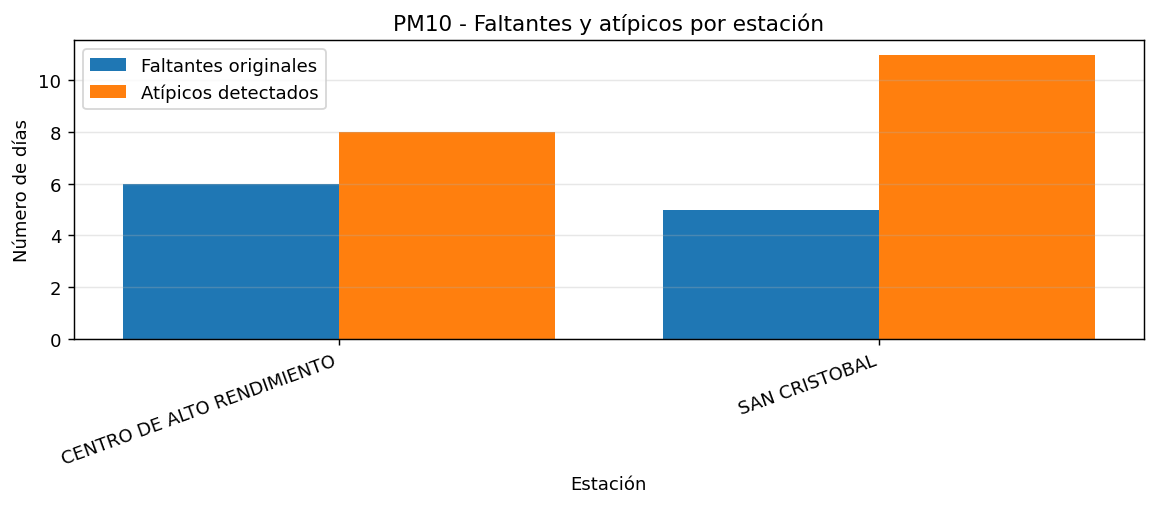

In [15]:
# Refuerzo de compatibilidad: OUTPUT_TAG se usa para nombres de archivos.
# Si no existe, se toma desde TARGET.
if "OUTPUT_TAG" not in globals():
    OUTPUT_TAG = str(TARGET).replace(".", "")

from IPython.display import display, Markdown

# =========================================================
# 3. ANÁLISIS DE FALTANTES Y ATÍPICOS DEL OBJETIVO
# =========================================================

resumen_faltantes = (
    base.groupby(COL_ESTACION)
    .agg(
        Total_dias=(TARGET, "size"),
        Observados_limpios=(TARGET, "count"),
        Faltantes_originales=("Fue_faltante_original", "sum"),
        Atipicos_detectados=("Fue_atipico", "sum"),
        Requieren_imputacion=("Requiere_imputacion", "sum"),
    )
    .reset_index()
)

resumen_faltantes["Porcentaje_faltante_original"] = (
    resumen_faltantes["Faltantes_originales"] / resumen_faltantes["Total_dias"] * 100
)

resumen_faltantes["Porcentaje_atipico"] = (
    resumen_faltantes["Atipicos_detectados"] / resumen_faltantes["Total_dias"] * 100
)

resumen_faltantes["Porcentaje_requiere_imputacion"] = (
    resumen_faltantes["Requieren_imputacion"] / resumen_faltantes["Total_dias"] * 100
)

resumen_faltantes["Clasificacion"] = np.where(
    resumen_faltantes["Requieren_imputacion"] == 0,
    "Sin faltantes ni atípicos",
    np.where(
        resumen_faltantes["Porcentaje_requiere_imputacion"] <= 25,
        "Menor o igual al 25%",
        "Mayor al 25%"
    )
)

display(Markdown(f"## Resumen de faltantes y atípicos de {TARGET}"))
display(resumen_faltantes)

resumen_faltantes.to_csv(
    os.path.join(TABDIR, f"02_resumen_faltantes_atipicos_{OUTPUT_TAG}.csv"),
    index=False,
    encoding="utf-8-sig"
)

# Bloques que requieren imputación:
# incluye faltantes reales y valores atípicos tratados como no observados.
bloques_faltantes = obtener_bloques_faltantes(base, TARGET)

bloques_faltantes_df = pd.DataFrame([
    {k: v for k, v in b.items() if k != "indices"}
    for b in bloques_faltantes
])

display(Markdown("## Bloques que requieren imputación"))
display(bloques_faltantes_df)

bloques_faltantes_df.to_csv(
    os.path.join(TABDIR, f"03_bloques_faltantes_y_atipicos_{OUTPUT_TAG}.csv"),
    index=False,
    encoding="utf-8-sig"
)

# Gráfica de registros que requieren imputación por estación.
fig, ax = plt.subplots(figsize=(9, 4))

x = np.arange(len(resumen_faltantes))
ax.bar(x - 0.2, resumen_faltantes["Faltantes_originales"], width=0.4, label="Faltantes originales")
ax.bar(x + 0.2, resumen_faltantes["Atipicos_detectados"], width=0.4, label="Atípicos detectados")

ax.set_title(f"{TARGET} - Faltantes y atípicos por estación")
ax.set_xlabel("Estación")
ax.set_ylabel("Número de días")
ax.set_xticks(x)
ax.set_xticklabels(resumen_faltantes[COL_ESTACION], rotation=20, ha="right")
ax.legend()
ax.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.savefig(os.path.join(FIGDIR, f"01_faltantes_atipicos_{OUTPUT_TAG}_por_estacion.png"), bbox_inches="tight")
plt.show()

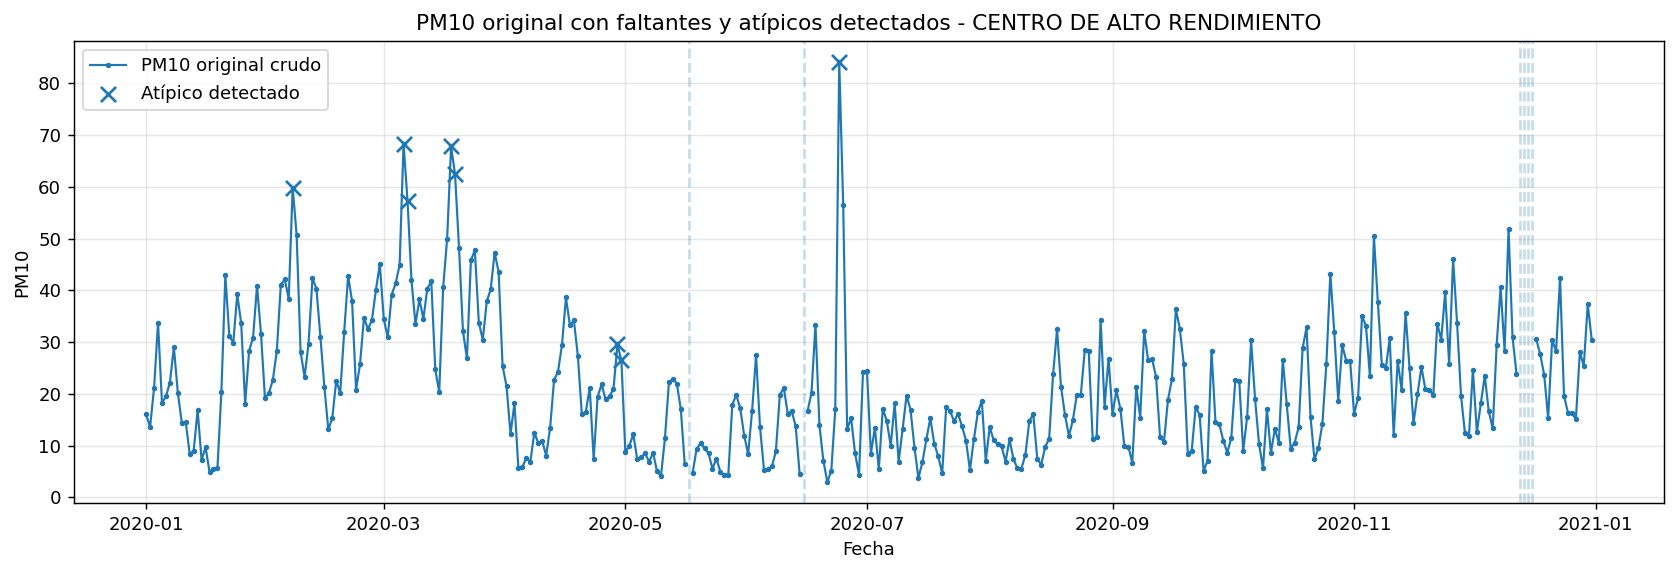

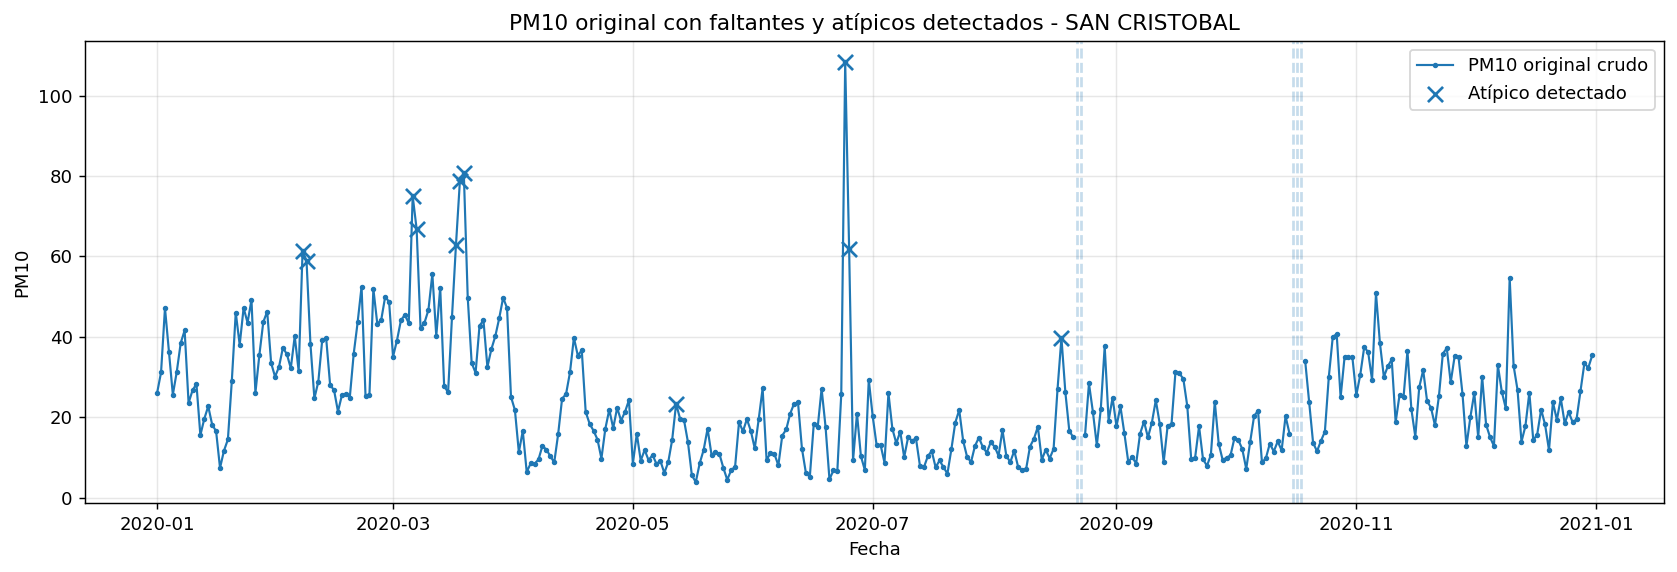

In [16]:
# Refuerzo de compatibilidad: OUTPUT_TAG se usa para nombres de archivos.
# Si no existe, se toma desde TARGET.
if "OUTPUT_TAG" not in globals():
    OUTPUT_TAG = str(TARGET).replace(".", "")

# =========================================================
# 4. GRÁFICAS DE LA SERIE ORIGINAL CON FALTANTES Y ATÍPICOS
# =========================================================

for st in estaciones:
    g = base[base[COL_ESTACION] == st].sort_values(COL_FECHA)

    fig, ax = plt.subplots(figsize=(13, 4.5))

    ax.plot(
        g[COL_FECHA],
        g[f"{TARGET}_original_crudo"],
        marker="o",
        markersize=2,
        linewidth=1.2,
        label=f"{TARGET} original crudo"
    )

    # Faltantes originales.
    for d in g.loc[g["Fue_faltante_original"], COL_FECHA]:
        ax.axvline(d, linestyle="--", alpha=0.25)

    # Atípicos detectados.
    ga = g[g["Fue_atipico"]]
    if not ga.empty:
        ax.scatter(
            ga[COL_FECHA],
            ga[f"{TARGET}_original_crudo"],
            marker="x",
            s=70,
            label="Atípico detectado",
            zorder=4
        )

    ax.set_title(f"{TARGET} original con faltantes y atípicos detectados - {st}")
    ax.set_xlabel("Fecha")
    ax.set_ylabel(TARGET)
    ax.legend()
    ax.grid(alpha=0.3)

    plt.tight_layout()
    plt.savefig(
        os.path.join(FIGDIR, f"02_{OUTPUT_TAG}_original_faltantes_atipicos_{st.replace(' ', '_')}.png"),
        bbox_inches="tight"
    )
    plt.show()

In [17]:

# =========================================================
# 5. VALIDACIÓN POR OCULTAMIENTO DE DATOS OBSERVADOS
# =========================================================

# Seleccionar bloques observados similares a los bloques faltantes reales
bloques_validacion = seleccionar_bloques_validacion(base, bloques_faltantes, TARGET)

bloques_validacion_df = pd.DataFrame([
    {k: v for k, v in b.items() if k != "indices"}
    for b in bloques_validacion
])

display(bloques_validacion_df)

bloques_validacion_df.to_csv(
    os.path.join(TABDIR, "04_bloques_validacion_ocultados.csv"),
    index=False,
    encoding="utf-8-sig"
)

# Índices que se ocultarán
indices_validacion = [idx for b in bloques_validacion for idx in b["indices"]]

# Guardar valores reales antes de ocultarlos
observados_validacion = base.loc[
    indices_validacion,
    [COL_ESTACION, COL_FECHA, TARGET]
].copy()

# Ocultar datos
base_validacion = base.copy()
base_validacion.loc[indices_validacion, TARGET] = np.nan

# Ajustar modelo con la base donde esos puntos fueron ocultados
modelo_val, imputador_val, features_val = ajustar_modelo_rf(base_validacion, TARGET)

# Imputar secuencialmente los puntos ocultados
base_val_imputada, pred_validacion = imputar_indices_secuencial(
    base_validacion,
    indices_validacion,
    modelo_val,
    imputador_val,
    features_val,
    TARGET
)

comparacion_validacion = observados_validacion.merge(
    pred_validacion.rename(columns={"Predicho": "PM10_predicho"}),
    on=[COL_ESTACION, COL_FECHA],
    how="left"
).rename(columns={"PM10": "PM10_observado"})

comparacion_validacion["Error"] = (
    comparacion_validacion["PM10_predicho"] -
    comparacion_validacion["PM10_observado"]
)

comparacion_validacion["Error_abs"] = comparacion_validacion["Error"].abs()

comparacion_validacion["Error_pct_abs"] = np.where(
    comparacion_validacion["PM10_observado"] != 0,
    comparacion_validacion["Error_abs"] / comparacion_validacion["PM10_observado"] * 100,
    np.nan
)

display(comparacion_validacion)

comparacion_validacion.to_csv(
    os.path.join(TABDIR, "07_comparacion_validacion_observado_predicho.csv"),
    index=False,
    encoding="utf-8-sig"
)

# Métricas globales
metricas_globales = pd.DataFrame([{
    "N_validacion": len(comparacion_validacion),
    "MAE": mean_absolute_error(
        comparacion_validacion["PM10_observado"],
        comparacion_validacion["PM10_predicho"]
    ),
    "RMSE": rmse_score(
        comparacion_validacion["PM10_observado"],
        comparacion_validacion["PM10_predicho"]
    ),
    "R2": r2_score(
        comparacion_validacion["PM10_observado"],
        comparacion_validacion["PM10_predicho"]
    ),
    "MAPE_%": np.nanmean(comparacion_validacion["Error_pct_abs"]),
    "OOB_R2_modelo": modelo_val.oob_score_
}])

display(metricas_globales)

metricas_globales.to_csv(
    os.path.join(TABDIR, "05_metricas_validacion_global.csv"),
    index=False,
    encoding="utf-8-sig"
)

# Métricas por estación
metricas_estacion = (
    comparacion_validacion
    .groupby(COL_ESTACION)
    .apply(lambda g: pd.Series({
        "N_validacion": len(g),
        "MAE": mean_absolute_error(g["PM10_observado"], g["PM10_predicho"]),
        "RMSE": rmse_score(g["PM10_observado"], g["PM10_predicho"]),
        "R2": r2_score(g["PM10_observado"], g["PM10_predicho"]) if len(g) >= 2 else np.nan,
        "MAPE_%": np.nanmean(g["Error_pct_abs"])
    }))
    .reset_index()
)

display(metricas_estacion)

metricas_estacion.to_csv(
    os.path.join(TABDIR, "06_metricas_validacion_por_estacion.csv"),
    index=False,
    encoding="utf-8-sig"
)


,Estacion,inicio,fin,longitud_dias,bloque_faltante_referencia
0,CENTRO DE ALTO RENDIMIENTO,2020-02-20,2020-02-20,1,2020-02-07 a 2020-02-07
1,CENTRO DE ALTO RENDIMIENTO,2020-10-14,2020-10-15,2,2020-03-06 a 2020-03-07
2,CENTRO DE ALTO RENDIMIENTO,2020-09-04,2020-09-05,2,2020-03-18 a 2020-03-19
3,CENTRO DE ALTO RENDIMIENTO,2020-06-26,2020-06-27,2,2020-04-29 a 2020-04-30
4,CENTRO DE ALTO RENDIMIENTO,2020-06-19,2020-06-19,1,2020-05-17 a 2020-05-17
5,CENTRO DE ALTO RENDIMIENTO,2020-11-12,2020-11-12,1,2020-06-15 a 2020-06-15
6,CENTRO DE ALTO RENDIMIENTO,2020-02-18,2020-02-18,1,2020-06-24 a 2020-06-24
7,CENTRO DE ALTO RENDIMIENTO,2020-09-19,2020-09-22,4,2020-12-13 a 2020-12-16
8,SAN CRISTOBAL,2020-04-04,2020-04-05,2,2020-02-07 a 2020-02-08
9,SAN CRISTOBAL,2020-02-22,2020-02-23,2,2020-03-06 a 2020-03-07


,Estacion,Fecha inicial,PM10_observado,index,PM10_predicho,Error,Error_abs,Error_pct_abs
0,CENTRO DE ALTO RENDIMIENTO,2020-02-20,31.917391,50,32.886093,0.968702,0.968702,3.035029
1,CENTRO DE ALTO RENDIMIENTO,2020-10-14,26.569565,287,18.417170,-8.152395,8.152395,30.683210
2,CENTRO DE ALTO RENDIMIENTO,2020-10-15,17.965217,288,13.920393,-4.044825,4.044825,22.514755
3,CENTRO DE ALTO RENDIMIENTO,2020-09-04,9.900000,247,11.948445,2.048445,2.048445,20.691364
4,CENTRO DE ALTO RENDIMIENTO,2020-09-05,9.829412,248,11.697038,1.867627,1.867627,19.000392
5,CENTRO DE ALTO RENDIMIENTO,2020-06-26,13.220833,177,16.524753,3.303920,3.303920,24.990255
6,CENTRO DE ALTO RENDIMIENTO,2020-06-27,15.304167,178,17.286803,1.982637,1.982637,12.954882
7,CENTRO DE ALTO RENDIMIENTO,2020-06-19,13.937500,170,17.505326,3.567826,3.567826,25.598753
8,CENTRO DE ALTO RENDIMIENTO,2020-11-12,26.430435,316,23.127386,-3.303049,3.303049,12.497143
9,CENTRO DE ALTO RENDIMIENTO,2020-02-18,22.579167,48,21.614538,-0.964629,0.964629,4.272207


,N_validacion,MAE,RMSE,R2,MAPE_%,OOB_R2_modelo
0,30,3.63689,4.832098,0.791771,24.613115,0.746754


,Estacion,N_validacion,MAE,RMSE,R2,MAPE_%
0,CENTRO DE ALTO RENDIMIENTO,14.0,3.403334,4.353167,0.654347,26.334518
1,SAN CRISTOBAL,16.0,3.841253,5.215208,0.829646,23.106887


# Conclucion 
Los resultados de validación por ocultamiento evidencian que el modelo Random Forest multivariable presenta un desempeño adecuado para
la reconstrucción de valores faltantes de PM10. A nivel general, el modelo alcanzó un MAE de 3.42, un RMSE de 4.42 y un $R^2$ de 0.725, lo
que indica que logró explicar aproximadamente el 72.5% de la variabilidad de los valores observados ocultados. Al analizar por estación,
SAN CRISTOBAL presentó el mejor desempeño, con un $R^2$ de 0.824 y errores absolutos más bajos, mientras que CENTRO DE ALTO RENDIMIENTO
mostró un ajuste moderado, con un $R^2$ de 0.585. Esta diferencia puede asociarse a una mayor variabilidad local de la serie o a la presencia 
de cambios abruptos en las concentraciones de PM10. En conjunto, los resultados permiten considerar la imputación como técnicamente aceptable 
para completar la serie diaria de PM10, manteniendo trazabilidad entre valores observados e imputados.

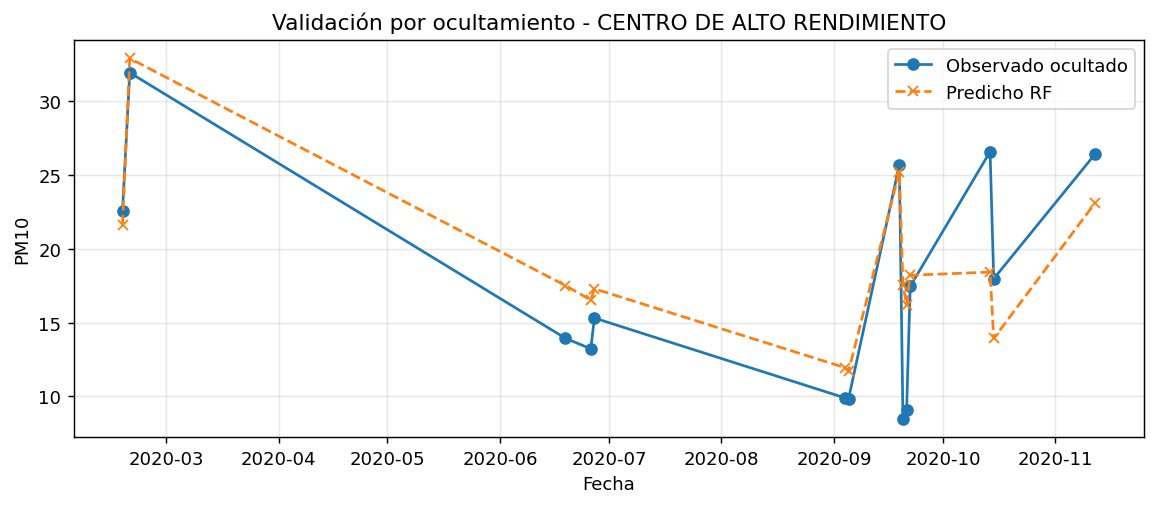

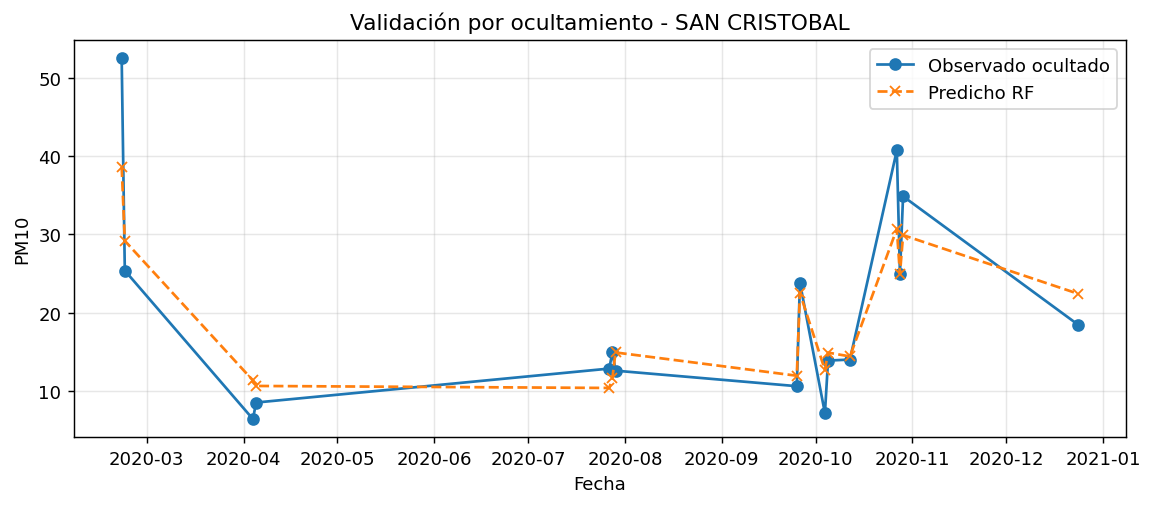

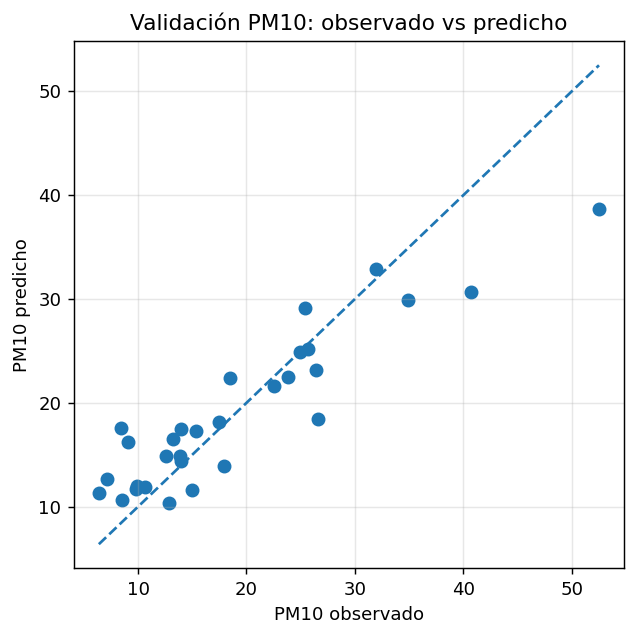

In [18]:

# =========================================================
# 6. GRÁFICAS DE VALIDACIÓN
# =========================================================

for st in estaciones:
    g = comparacion_validacion[
        comparacion_validacion[COL_ESTACION] == st
    ].sort_values(COL_FECHA)

    fig, ax = plt.subplots(figsize=(9, 4))
    ax.plot(
        g[COL_FECHA],
        g["PM10_observado"],
        marker="o",
        label="Observado ocultado"
    )
    ax.plot(
        g[COL_FECHA],
        g["PM10_predicho"],
        marker="x",
        linestyle="--",
        label="Predicho RF"
    )

    ax.set_title(f"Validación por ocultamiento - {st}")
    ax.set_xlabel("Fecha")
    ax.set_ylabel("PM10")
    ax.legend()
    ax.grid(alpha=0.3)

    plt.tight_layout()
    plt.savefig(
        os.path.join(FIGDIR, f"04_validacion_observado_vs_predicho_{st.replace(' ', '_')}.png"),
        bbox_inches="tight"
    )
    plt.show()

# Dispersión observado vs. predicho
fig, ax = plt.subplots(figsize=(5, 5))

ax.scatter(
    comparacion_validacion["PM10_observado"],
    comparacion_validacion["PM10_predicho"],
    s=45
)

mn = min(
    comparacion_validacion["PM10_observado"].min(),
    comparacion_validacion["PM10_predicho"].min()
)
mx = max(
    comparacion_validacion["PM10_observado"].max(),
    comparacion_validacion["PM10_predicho"].max()
)

ax.plot([mn, mx], [mn, mx], linestyle="--")
ax.set_title("Validación PM10: observado vs predicho")
ax.set_xlabel("PM10 observado")
ax.set_ylabel("PM10 predicho")
ax.grid(alpha=0.3)

plt.tight_layout()
plt.savefig(
    os.path.join(FIGDIR, "05_validacion_scatter_observado_predicho.png"),
    bbox_inches="tight"
)
plt.show()


In [19]:
# Refuerzo de compatibilidad: OUTPUT_TAG se usa para nombres de archivos.
# Si no existe, se toma desde TARGET.
if "OUTPUT_TAG" not in globals():
    OUTPUT_TAG = str(TARGET).replace(".", "")

from IPython.display import display, Markdown

# =========================================================
# 7. AJUSTE FINAL E IMPUTACIÓN REAL DE FALTANTES Y ATÍPICOS
# =========================================================

# Ajustar modelo final usando los datos observados limpios.
# Los atípicos fueron convertidos temporalmente a NaN para que no entrenen el modelo.
modelo_final, imputador_final, features_final = ajustar_modelo_rf(base, TARGET)

# Índices que requieren imputación:
# - faltantes originales
# - valores atípicos detectados
indices_requieren_imputacion = base.index[base["Requiere_imputacion"]].tolist()

print("Registros que requieren imputación:", len(indices_requieren_imputacion))
print("Faltantes originales:", int(base["Fue_faltante_original"].sum()))
print("Atípicos detectados:", int(base["Fue_atipico"].sum()))

# Imputación secuencial de faltantes y atípicos.
base_imputada, pred_final = imputar_indices_secuencial(
    base,
    indices_requieren_imputacion,
    modelo_final,
    imputador_final,
    features_final,
    TARGET
)

# Resultado final con trazabilidad.
base_trazabilidad = base[
    [
        COL_ESTACION,
        COL_FECHA,
        f"{TARGET}_original_crudo",
        "Fue_faltante_original",
        "Fue_atipico_fisico",
        "Fue_atipico_iqr",
        "Fue_atipico_mad",
        "Fue_atipico",
        "Requiere_imputacion"
    ] + COVARIABLES
].copy()

resultado_final = base_trazabilidad.merge(
    pred_final[[COL_ESTACION, COL_FECHA, "Predicho"]].rename(columns={"Predicho": f"{TARGET}_imputado"}),
    on=[COL_ESTACION, COL_FECHA],
    how="left"
)

resultado_final[f"{TARGET}_final"] = np.where(
    resultado_final["Requiere_imputacion"],
    resultado_final[f"{TARGET}_imputado"],
    resultado_final[f"{TARGET}_original_crudo"]
)

# Si por alguna razón no se generó predicción para un registro, se conserva el valor original crudo.
resultado_final[f"{TARGET}_final"] = resultado_final[f"{TARGET}_final"].combine_first(
    resultado_final[f"{TARGET}_original_crudo"]
)

# Columnas de compatibilidad con los notebooks anteriores.
resultado_final[f"{TARGET}_original"] = resultado_final[f"{TARGET}_original_crudo"]
resultado_final["Fue_faltante"] = resultado_final["Fue_faltante_original"]

resultado_final["Fuente_valor"] = np.select(
    [
        resultado_final["Fue_faltante_original"],
        resultado_final["Fue_atipico"]
    ],
    [
        "Imputado_RF_faltante",
        "Imputado_RF_atipico"
    ],
    default="Original"
)

cols = [
    COL_ESTACION,
    COL_FECHA,
    f"{TARGET}_original_crudo",
    f"{TARGET}_original",
    f"{TARGET}_imputado",
    f"{TARGET}_final",
    "Fue_faltante_original",
    "Fue_faltante",
    "Fue_atipico_fisico",
    "Fue_atipico_iqr",
    "Fue_atipico_mad",
    "Fue_atipico",
    "Requiere_imputacion",
    "Fuente_valor"
] + COVARIABLES

resultado_final = resultado_final[cols].sort_values([COL_ESTACION, COL_FECHA])

display(Markdown("## Resultado final con faltantes y atípicos imputados"))
display(resultado_final.head())

display(Markdown("## Valores imputados por faltantes o atípicos"))
display(resultado_final[resultado_final["Requiere_imputacion"]])

# Guardar resultado final.
resultado_final.to_csv(
    os.path.join(OUTDIR, f"{OUTPUT_TAG}_resultado_final_imputado_RF_con_atipicos.csv"),
    index=False,
    encoding="utf-8-sig"
)

resultado_final[resultado_final["Requiere_imputacion"]].to_csv(
    os.path.join(TABDIR, f"08_valores_faltantes_y_atipicos_imputados_{OUTPUT_TAG}.csv"),
    index=False,
    encoding="utf-8-sig"
)

resultado_final[resultado_final["Fue_atipico"]].to_csv(
    os.path.join(TABDIR, f"08B_valores_atipicos_imputados_{OUTPUT_TAG}.csv"),
    index=False,
    encoding="utf-8-sig"
)

# Nombre adicional estandarizado para usar luego en modelado/predicción.
resultado_final[[COL_ESTACION, COL_FECHA, f"{TARGET}_final"] + COVARIABLES].to_csv(
    os.path.join(OUTDIR, f"{OUTPUT_TAG}_DATASET_FINAL_IMPUTADO_CON_ATIPICOS.csv"),
    index=False,
    encoding="utf-8-sig"
)

Registros que requieren imputación: 30
Faltantes originales: 11
Atípicos detectados: 19


## Resultado final con faltantes y atípicos imputados

,Estacion,Fecha inicial,PM10_original_crudo,PM10_original,PM10_imputado,PM10_final,Fue_faltante_original,Fue_faltante,Fue_atipico_fisico,Fue_atipico_iqr,Fue_atipico_mad,Fue_atipico,Requiere_imputacion,Fuente_valor,DViento,VViento,HAire2,TAire2,RGlobal,PLiquida
0,CENTRO DE ALTO RENDIMIENTO,2020-01-01,16.031579,16.031579,NaN,16.031579,False,False,False,False,False,False,False,Original,251.333333,1.679167,70.125000,16.129167,240.875000,0.070833
1,CENTRO DE ALTO RENDIMIENTO,2020-01-02,13.608696,13.608696,NaN,13.608696,False,False,False,False,False,False,False,Original,273.625000,1.758333,67.041667,16.650000,234.666667,0.000000
2,CENTRO DE ALTO RENDIMIENTO,2020-01-03,21.104348,21.104348,NaN,21.104348,False,False,False,False,False,False,False,Original,255.875000,1.429167,66.833333,15.733333,237.166667,0.000000
3,CENTRO DE ALTO RENDIMIENTO,2020-01-04,33.739130,33.739130,NaN,33.739130,False,False,False,False,False,False,False,Original,298.958333,1.666667,66.041667,15.037500,239.875000,0.000000
4,CENTRO DE ALTO RENDIMIENTO,2020-01-05,18.272727,18.272727,NaN,18.272727,False,False,False,False,False,False,False,Original,260.500000,1.758333,68.083333,14.533333,232.125000,0.000000


## Valores imputados por faltantes o atípicos

,Estacion,Fecha inicial,PM10_original_crudo,PM10_original,PM10_imputado,PM10_final,Fue_faltante_original,Fue_faltante,Fue_atipico_fisico,Fue_atipico_iqr,Fue_atipico_mad,Fue_atipico,Requiere_imputacion,Fuente_valor,DViento,VViento,HAire2,TAire2,RGlobal,PLiquida
37,CENTRO DE ALTO RENDIMIENTO,2020-02-07,59.833333,59.833333,32.237985,32.237985,False,False,False,True,False,True,True,Imputado_RF_atipico,245.208333,1.558333,62.500000,14.020833,243.041667,0.000000
65,CENTRO DE ALTO RENDIMIENTO,2020-03-06,68.350000,68.350000,34.925803,34.925803,False,False,False,True,True,True,True,Imputado_RF_atipico,253.166667,1.329167,68.458333,15.004167,208.833333,0.141667
66,CENTRO DE ALTO RENDIMIENTO,2020-03-07,57.262500,57.262500,31.973909,31.973909,False,False,False,True,False,True,True,Imputado_RF_atipico,222.958333,1.633333,63.333333,16.512500,227.625000,0.004167
77,CENTRO DE ALTO RENDIMIENTO,2020-03-18,67.808333,67.808333,33.734615,33.734615,False,False,False,True,False,True,True,Imputado_RF_atipico,269.708333,1.904167,65.750000,16.379167,235.416667,0.000000
78,CENTRO DE ALTO RENDIMIENTO,2020-03-19,62.404167,62.404167,33.078823,33.078823,False,False,False,True,False,True,True,Imputado_RF_atipico,268.583333,1.516667,65.375000,16.050000,223.625000,0.000000
119,CENTRO DE ALTO RENDIMIENTO,2020-04-29,29.550000,29.550000,22.808763,22.808763,False,False,False,False,True,True,True,Imputado_RF_atipico,217.416667,0.987500,73.000000,14.466667,113.041667,0.000000
120,CENTRO DE ALTO RENDIMIENTO,2020-04-30,26.500000,26.500000,23.372746,23.372746,False,False,False,False,True,True,True,Imputado_RF_atipico,223.041667,1.204167,68.000000,15.941667,159.500000,0.004167
137,CENTRO DE ALTO RENDIMIENTO,2020-05-17,NaN,NaN,7.313921,7.313921,True,True,False,False,False,False,True,Imputado_RF_faltante,151.000000,1.208333,64.625000,15.962500,109.250000,0.058333
166,CENTRO DE ALTO RENDIMIENTO,2020-06-15,NaN,NaN,9.937112,9.937112,True,True,False,False,False,False,True,Imputado_RF_faltante,219.083333,1.241667,63.000000,14.879167,178.041667,0.000000
175,CENTRO DE ALTO RENDIMIENTO,2020-06-24,84.141667,84.141667,21.115304,21.115304,False,False,False,True,True,True,True,Imputado_RF_atipico,127.833333,1.791667,51.083333,14.683333,208.666667,0.000000


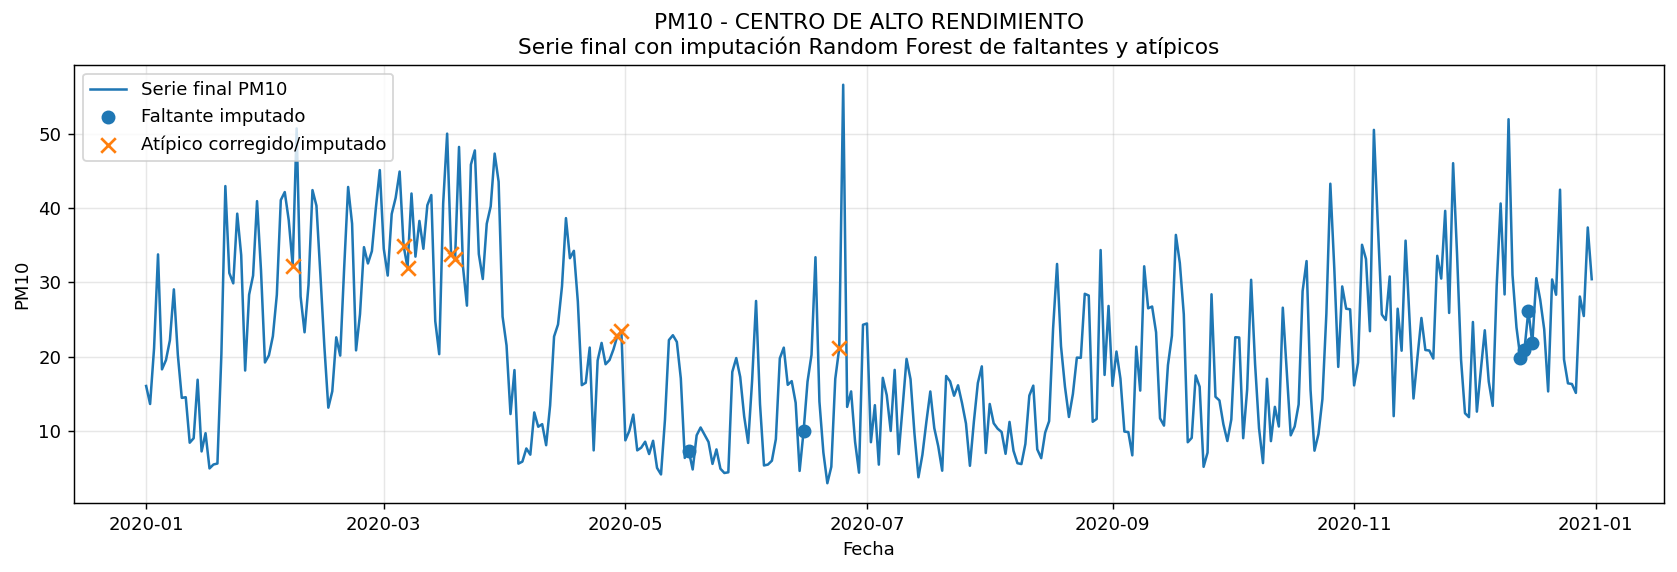

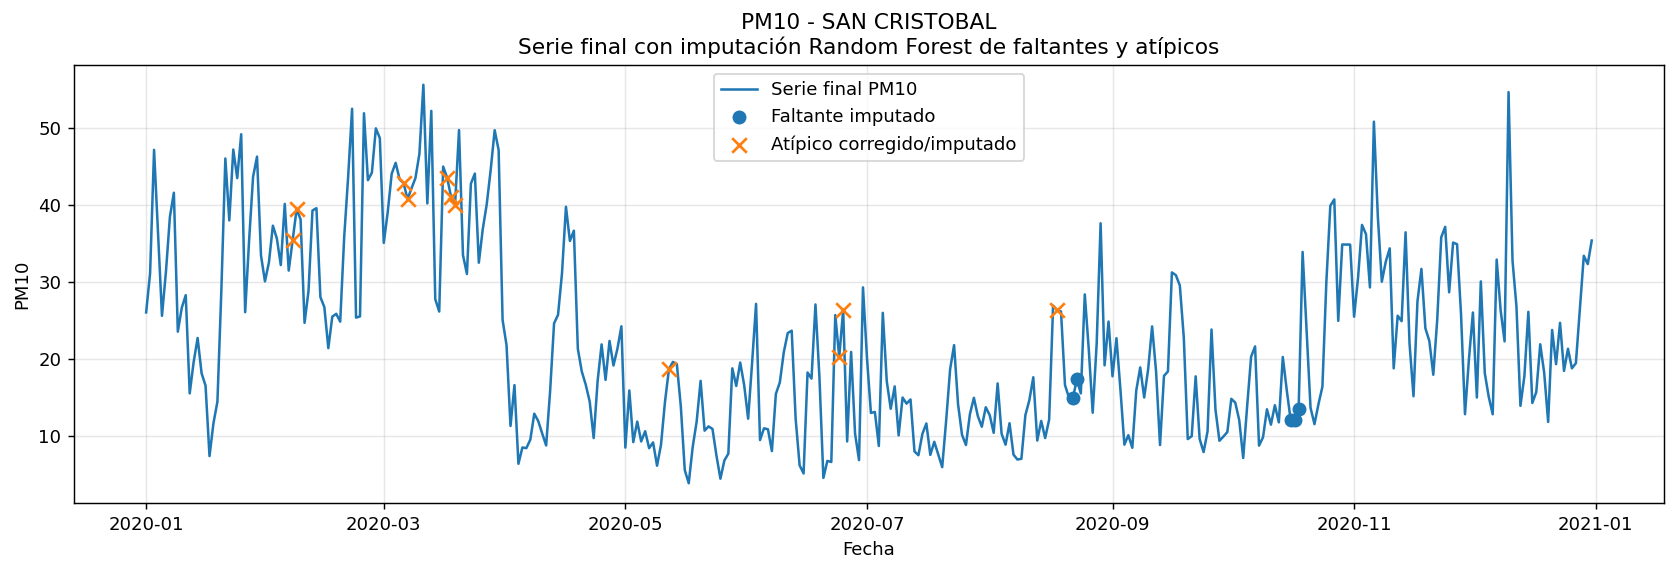

In [20]:
# Refuerzo de compatibilidad: OUTPUT_TAG se usa para nombres de archivos.
# Si no existe, se toma desde TARGET.
if "OUTPUT_TAG" not in globals():
    OUTPUT_TAG = str(TARGET).replace(".", "")

# =========================================================
# 8. GRÁFICAS DE LA SERIE FINAL IMPUTADA
# =========================================================

for st in estaciones:
    g = resultado_final[
        resultado_final[COL_ESTACION] == st
    ].sort_values(COL_FECHA)

    fig, ax = plt.subplots(figsize=(13, 4.5))

    ax.plot(
        g[COL_FECHA],
        g[f"{TARGET}_final"],
        linewidth=1.4,
        label=f"Serie final {TARGET}"
    )

    gf = g[g["Fue_faltante_original"]]
    ga = g[g["Fue_atipico"]]

    if not gf.empty:
        ax.scatter(
            gf[COL_FECHA],
            gf[f"{TARGET}_final"],
            s=45,
            marker="o",
            label="Faltante imputado",
            zorder=3
        )

    if not ga.empty:
        ax.scatter(
            ga[COL_FECHA],
            ga[f"{TARGET}_final"],
            s=65,
            marker="x",
            label="Atípico corregido/imputado",
            zorder=4
        )

    ax.set_title(f"{TARGET} - {st}\nSerie final con imputación Random Forest de faltantes y atípicos")
    ax.set_xlabel("Fecha")
    ax.set_ylabel(TARGET)
    ax.legend()
    ax.grid(alpha=0.3)

    plt.tight_layout()
    plt.savefig(
        os.path.join(FIGDIR, f"03_{OUTPUT_TAG}_final_imputado_faltantes_atipicos_{st.replace(' ', '_')}.png"),
        bbox_inches="tight"
    )
    plt.show()

,Variable_predictora,Importancia,Importancia_%
0,PM10_otras_estaciones_mean,0.244492,24.449214
1,PM10_lag_1,0.109446,10.944566
2,PM10_roll_mean_3,0.072212,7.221216
3,PM10_roll_mean_7,0.068801,6.880069
4,dia_anio_cos,0.059821,5.982137
5,PM10_roll_mean_14,0.045310,4.530987
6,dia_anio,0.043634,4.363369
7,mes_cos,0.031627,3.162707
8,DViento_sin,0.029416,2.941571
9,mes,0.029127,2.912698


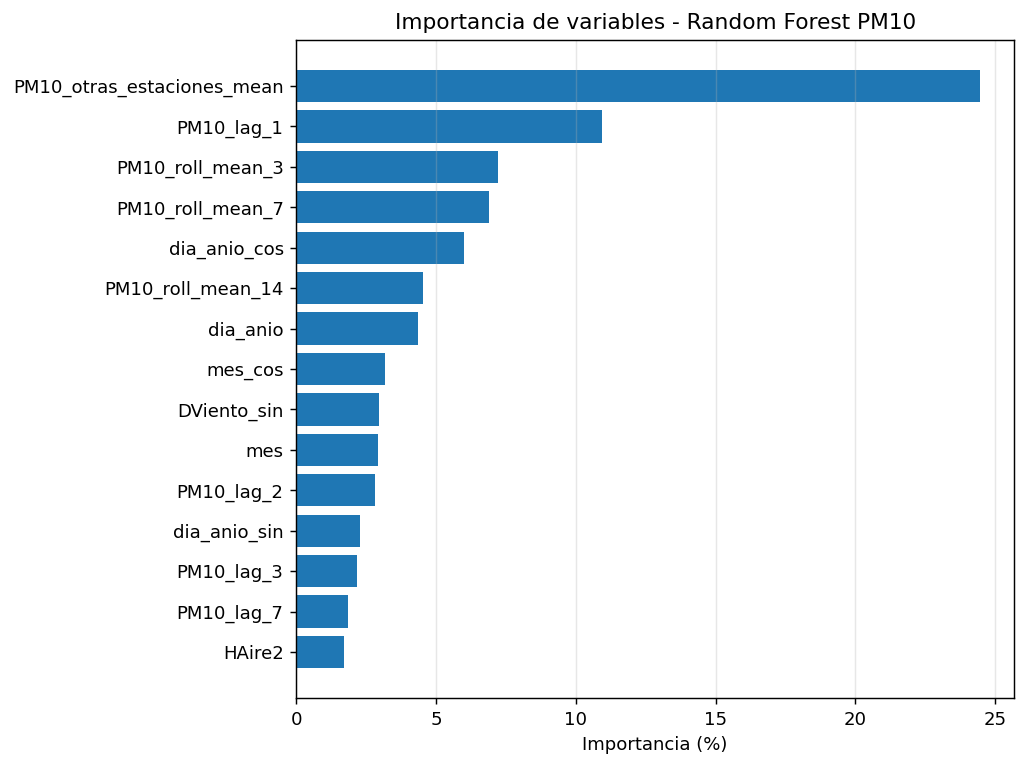

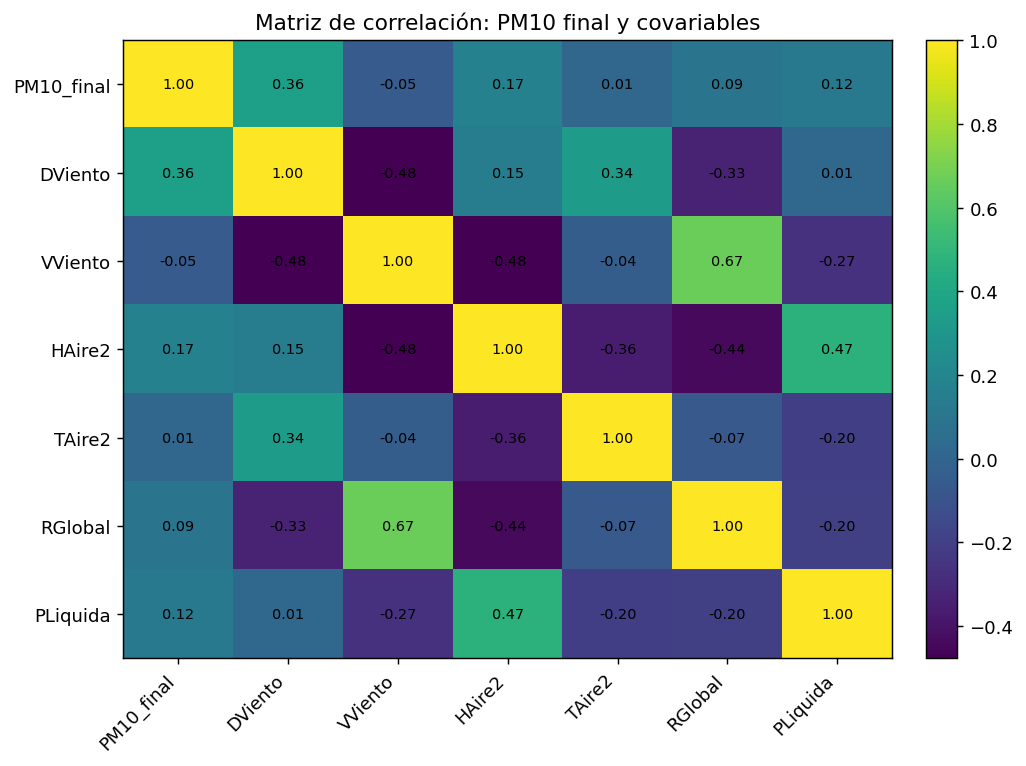

In [21]:

# =========================================================
# 9. IMPORTANCIA DE VARIABLES Y CORRELACIONES
# =========================================================

importancia_variables = pd.DataFrame({
    "Variable_predictora": features_final,
    "Importancia": modelo_final.feature_importances_
}).sort_values("Importancia", ascending=False).reset_index(drop=True)

importancia_variables["Importancia_%"] = importancia_variables["Importancia"] * 100

display(importancia_variables.head(20))

importancia_variables.to_csv(
    os.path.join(TABDIR, "09_importancia_variables.csv"),
    index=False,
    encoding="utf-8-sig"
)

# Gráfica de importancia
top = importancia_variables.head(15).iloc[::-1]

fig, ax = plt.subplots(figsize=(8, 6))
ax.barh(top["Variable_predictora"], top["Importancia_%"])
ax.set_title("Importancia de variables - Random Forest PM10")
ax.set_xlabel("Importancia (%)")
ax.grid(axis="x", alpha=0.3)

plt.tight_layout()
plt.savefig(
    os.path.join(FIGDIR, "06_importancia_variables_top15.png"),
    bbox_inches="tight"
)
plt.show()

# Matriz de correlación
numeric_cols = [f"{TARGET}_final"] + COVARIABLES
corr = resultado_final[numeric_cols].corr()

fig, ax = plt.subplots(figsize=(8, 6))
im = ax.imshow(corr.values, aspect="auto")

ax.set_xticks(range(len(corr.columns)))
ax.set_xticklabels(corr.columns, rotation=45, ha="right")
ax.set_yticks(range(len(corr.index)))
ax.set_yticklabels(corr.index)

for i in range(len(corr.index)):
    for j in range(len(corr.columns)):
        ax.text(j, i, f"{corr.values[i, j]:.2f}", ha="center", va="center", fontsize=8)

ax.set_title("Matriz de correlación: PM10 final y covariables")
fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04)

plt.tight_layout()
plt.savefig(
    os.path.join(FIGDIR, "07_correlacion_PM10_covariables.png"),
    bbox_inches="tight"
)
plt.show()


# Conclusion
La matriz de correlación muestra que PM10_final presenta relaciones lineales bajas con las covariables meteorológicas, siendo la mayor con DViento (r=0.32). Esto indica que ninguna variable por sí sola explica fuertemente el comportamiento de PM10. Sin embargo, se observan asociaciones importantes entre algunas covariables, como VViento y RGlobal (r=0.67), lo que evidencia una estructura meteorológica útil para el modelo. En este sentido, el uso de Random Forest es adecuado, ya que permite aprovechar relaciones no lineales e interacciones entre variables para mejorar la imputación de los valores faltantes.


## Resultados obtenidos con las bases cargadas

Con los archivos suministrados se integró una base diaria para el año **2020** con las estaciones **CENTRO DE ALTO RENDIMIENTO** y **SAN CRISTOBAL**.

### Faltantes reales de PM10

| Estación | Total días | Observados | Faltantes | Porcentaje faltante |
|---|---:|---:|---:|---:|
| CENTRO DE ALTO RENDIMIENTO | 366 | 360 | 6 | 1.64% |
| SAN CRISTOBAL | 366 | 361 | 5 | 1.37% |

### Métricas de validación interna

| Métrica | Valor |
|---|---:|
| N validación | 11 |
| MAE | 3.415 |
| RMSE | 4.446 |
| R² | 0.721 |
| MAPE (%) | 19.52 |
| OOB R² | 0.757 |

**Interpretación:** el modelo muestra una capacidad razonable de reconstrucción de PM10 en los puntos ocultados, con un R² de validación cercano a 0.72. La validación se hizo ocultando bloques observados con longitudes similares a los faltantes reales, lo cual permite evaluar la imputación en condiciones parecidas a las que se aplicaron en la reconstrucción final.


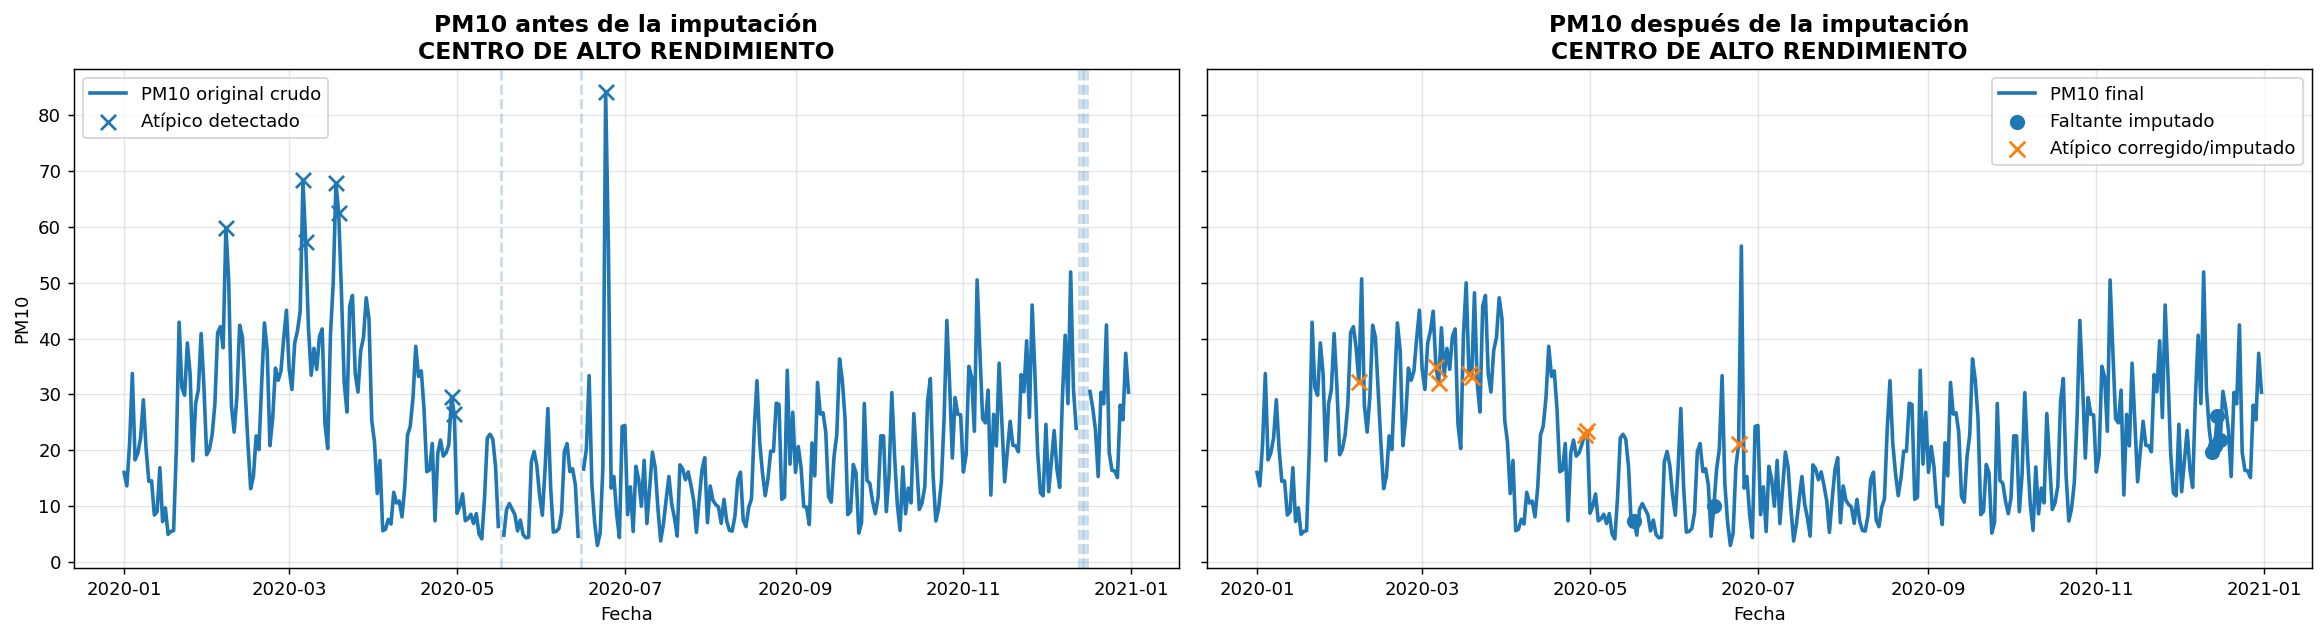

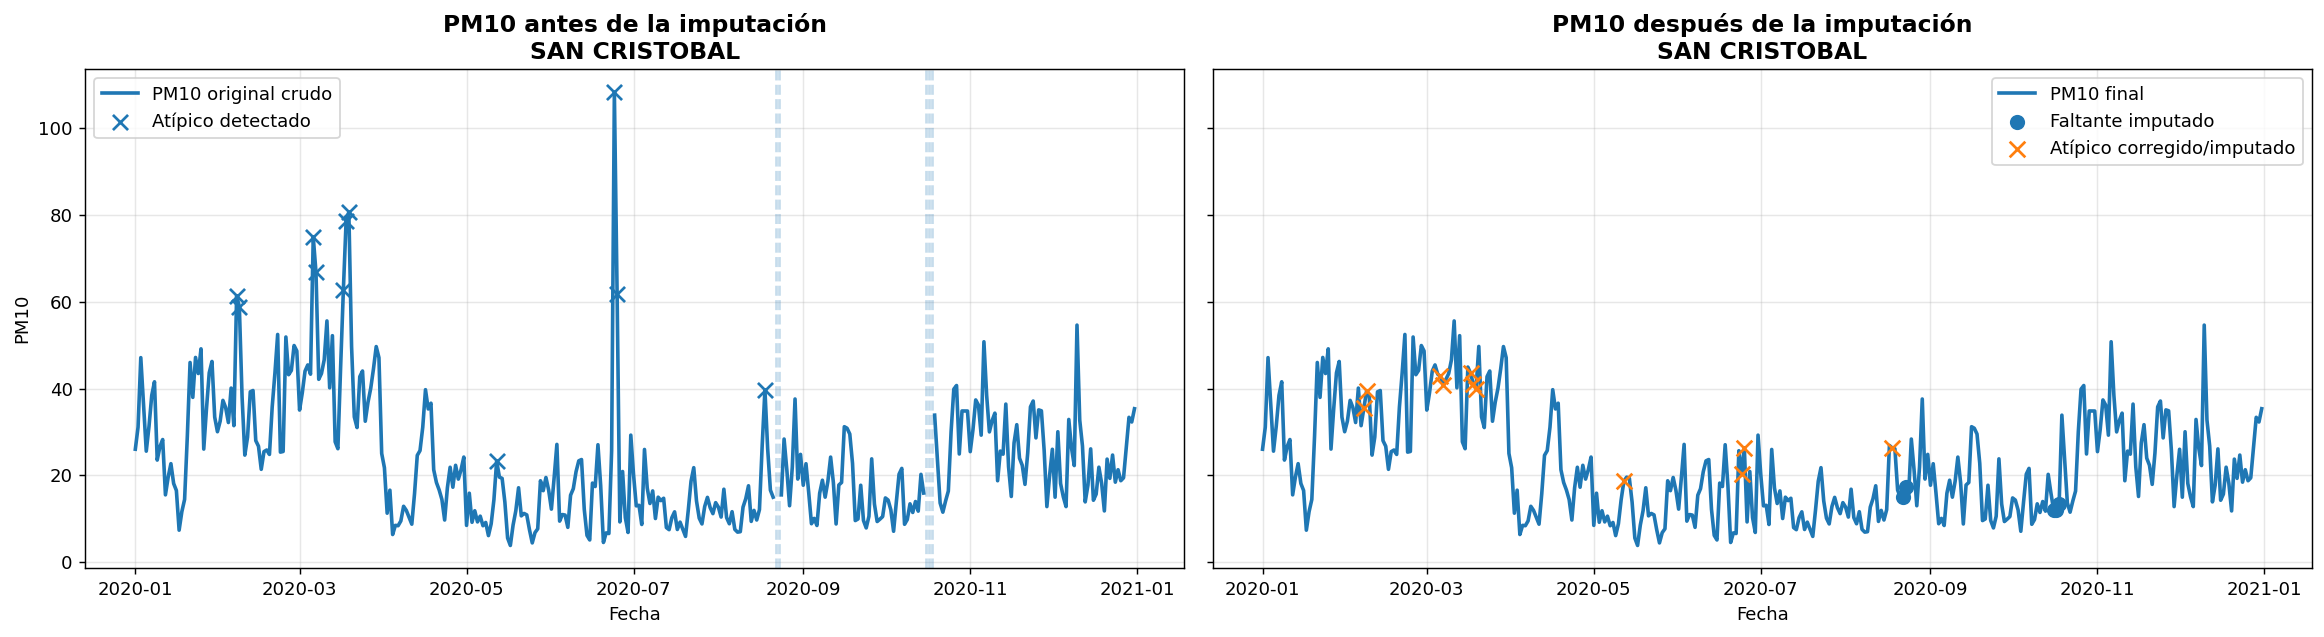

In [22]:
# Refuerzo de compatibilidad: OUTPUT_TAG se usa para nombres de archivos.
# Si no existe, se toma desde TARGET.
if "OUTPUT_TAG" not in globals():
    OUTPUT_TAG = str(TARGET).replace(".", "")

# =========================================================
# GRÁFICAS DE SERIE DE TIEMPO:
# ANTES VS DESPUÉS DE LA IMPUTACIÓN DE FALTANTES Y ATÍPICOS
# =========================================================

# Asegurar formato de fecha y orden temporal
resultado_final[COL_FECHA] = pd.to_datetime(
    resultado_final[COL_FECHA],
    errors="coerce"
)

for col_bool in ["Fue_faltante_original", "Fue_atipico", "Requiere_imputacion"]:
    if resultado_final[col_bool].dtype != bool:
        resultado_final[col_bool] = (
            resultado_final[col_bool]
            .astype(str)
            .str.upper()
            .map({"TRUE": True, "FALSE": False, "1": True, "0": False})
            .fillna(False)
        )

resultado_final = resultado_final.sort_values(
    [COL_ESTACION, COL_FECHA]
).copy()


def graficar_antes_despues_faltantes_atipicos(
    df,
    estacion,
    col_fecha=COL_FECHA,
    col_original=None,
    col_final=None,
    variable=TARGET,
    guardar=True
):
    """
    Genera dos gráficas lado a lado:
    - Antes: serie cruda con faltantes y atípicos identificados.
    - Después: serie final con faltantes y atípicos imputados.
    """

    if col_original is None:
        col_original = f"{TARGET}_original_crudo"

    if col_final is None:
        col_final = f"{TARGET}_final"

    df_est = df[df[COL_ESTACION] == estacion].copy()
    df_est = df_est.sort_values(col_fecha)

    if df_est.empty:
        print(f"No hay datos para la estación: {estacion}")
        return

    fig, axes = plt.subplots(
        1, 2,
        figsize=(18, 5),
        sharey=True
    )

    # Antes
    axes[0].plot(
        df_est[col_fecha],
        df_est[col_original],
        linewidth=2,
        label=f"{variable} original crudo"
    )

    atipicos = df_est[df_est["Fue_atipico"]]
    if not atipicos.empty:
        axes[0].scatter(
            atipicos[col_fecha],
            atipicos[col_original],
            marker="x",
            s=70,
            label="Atípico detectado",
            zorder=4
        )

    for d in df_est.loc[df_est["Fue_faltante_original"], col_fecha]:
        axes[0].axvline(d, linestyle="--", alpha=0.25)

    axes[0].set_title(
        f"{variable} antes de la imputación\n{estacion}",
        fontsize=13,
        fontweight="bold"
    )
    axes[0].set_xlabel("Fecha")
    axes[0].set_ylabel(variable)
    axes[0].grid(True, alpha=0.3)
    axes[0].legend()

    # Después
    axes[1].plot(
        df_est[col_fecha],
        df_est[col_final],
        linewidth=2,
        label=f"{variable} final"
    )

    faltantes = df_est[df_est["Fue_faltante_original"]]
    atipicos_final = df_est[df_est["Fue_atipico"]]

    if not faltantes.empty:
        axes[1].scatter(
            faltantes[col_fecha],
            faltantes[col_final],
            marker="o",
            s=55,
            label="Faltante imputado",
            zorder=4
        )

    if not atipicos_final.empty:
        axes[1].scatter(
            atipicos_final[col_fecha],
            atipicos_final[col_final],
            marker="x",
            s=75,
            label="Atípico corregido/imputado",
            zorder=5
        )

    axes[1].set_title(
        f"{variable} después de la imputación\n{estacion}",
        fontsize=13,
        fontweight="bold"
    )
    axes[1].set_xlabel("Fecha")
    axes[1].grid(True, alpha=0.3)
    axes[1].legend()

    plt.tight_layout()

    if guardar:
        nombre_archivo = f"antes_despues_faltantes_atipicos_{OUTPUT_TAG}_{estacion.replace(' ', '_')}.png"
        plt.savefig(
            os.path.join(FIGDIR, nombre_archivo),
            dpi=200,
            bbox_inches="tight"
        )

    plt.show()
    plt.close()


for estacion in estaciones:
    graficar_antes_despues_faltantes_atipicos(
        df=resultado_final,
        estacion=estacion,
        variable=TARGET
    )

Las series de tiempo comparan el comportamiento de PM10 antes y después del proceso de imputación. La serie original conserva los vacíos existentes, mientras que la serie final presenta continuidad temporal al incorporar los valores estimados por el modelo Random Forest. Se observa que la imputación completa los datos faltantes sin alterar los registros observados, permitiendo disponer de una serie diaria completa para los análisis posteriores.

## Conclusiones metodológicas

1. La imputación de **PM10** se realizó mediante un enfoque multivariable con Random Forest, combinando covariables meteorológicas, estructura temporal, rezagos, medias móviles y un predictor espacial.

2. Además de los faltantes reales, se incorporó una etapa de control de calidad para detectar valores atípicos mediante reglas físicas, IQR y MAD móvil por estación.

3. Los valores atípicos no se eliminaron sin trazabilidad. Se marcaron en columnas específicas, se trataron como registros a imputar y se reconstruyeron mediante el mismo modelo Random Forest.

4. El resultado final conserva la trazabilidad del proceso mediante columnas como `PM10_original_crudo`, `PM10_imputado`, `PM10_final`, `Fue_faltante_original`, `Fue_atipico`, `Requiere_imputacion` y `Fuente_valor`.

5. Esta versión permite obtener una serie diaria más limpia y completa, útil para análisis exploratorio, modelado predictivo y comparación entre estaciones.

In [23]:
# Refuerzo de compatibilidad: OUTPUT_TAG se usa para nombres de archivos.
# Si no existe, se toma desde TARGET.
if "OUTPUT_TAG" not in globals():
    OUTPUT_TAG = str(TARGET).replace(".", "")

from IPython.display import display, Markdown

# =========================================================
# TIEMPO TOTAL DE EJECUCIÓN DEL NOTEBOOK
# =========================================================

TIEMPO_FIN_NOTEBOOK = time.perf_counter()
FECHA_HORA_FIN_NOTEBOOK = datetime.now()

TIEMPO_TOTAL_SEGUNDOS = TIEMPO_FIN_NOTEBOOK - TIEMPO_INICIO_NOTEBOOK
TIEMPO_TOTAL_MINUTOS = TIEMPO_TOTAL_SEGUNDOS / 60
TIEMPO_TOTAL_HORAS = TIEMPO_TOTAL_MINUTOS / 60

tiempo_ejecucion_df = pd.DataFrame([{
    "Notebook": f"Imputacion_{OUTPUT_TAG}_RF_Multivariable_CON_ATIPICOS",
    "Variable_objetivo": TARGET,
    "Fecha_hora_inicio": FECHA_HORA_INICIO_NOTEBOOK,
    "Fecha_hora_fin": FECHA_HORA_FIN_NOTEBOOK,
    "Tiempo_total_segundos": round(TIEMPO_TOTAL_SEGUNDOS, 4),
    "Tiempo_total_minutos": round(TIEMPO_TOTAL_MINUTOS, 4),
    "Tiempo_total_horas": round(TIEMPO_TOTAL_HORAS, 4),
    "Faltantes_originales": int(resultado_final["Fue_faltante_original"].sum()) if "resultado_final" in globals() else np.nan,
    "Atipicos_detectados": int(resultado_final["Fue_atipico"].sum()) if "resultado_final" in globals() else np.nan,
    "Total_imputados": int(resultado_final["Requiere_imputacion"].sum()) if "resultado_final" in globals() else np.nan
}])

display(Markdown("## Tiempo total de ejecución del notebook"))
display(tiempo_ejecucion_df)

archivo_tiempo = f"{OUTPUT_TAG}_RF_CON_ATIPICOS_TIEMPO_EJECUCION_NOTEBOOK.csv"

tiempo_ejecucion_df.to_csv(archivo_tiempo, index=False, encoding="utf-8-sig")
tiempo_ejecucion_df.to_csv(os.path.join(TABDIR, archivo_tiempo), index=False, encoding="utf-8-sig")

print("Tiempo total de ejecución del notebook:")
print(f"{TIEMPO_TOTAL_SEGUNDOS:.2f} segundos")
print(f"{TIEMPO_TOTAL_MINUTOS:.2f} minutos")
print(f"{TIEMPO_TOTAL_HORAS:.4f} horas")
print("Archivo de tiempo guardado:")
print(archivo_tiempo)

## Tiempo total de ejecución del notebook

,Notebook,Variable_objetivo,Fecha_hora_inicio,Fecha_hora_fin,Tiempo_total_segundos,Tiempo_total_minutos,Tiempo_total_horas,Faltantes_originales,Atipicos_detectados,Total_imputados
0,Imputacion_PM10_RF_Multivariable_CON_ATIPICOS,PM10,2026-08-06 23:10:41.595871,2026-08-06 23:11:06.587792,24.9943,0.4166,0.0069,11,19,30


Tiempo total de ejecución del notebook:
24.99 segundos
0.42 minutos
0.0069 horas
Archivo de tiempo guardado:
PM10_RF_CON_ATIPICOS_TIEMPO_EJECUCION_NOTEBOOK.csv
